# KKBox Customer Churn Prediction Using Machine Learning

## 1. Project Objective

The objective of this project is to preprocess customer subscription data from the KKBox dataset and develop a machine learning model to predict whether a customer will churn.

The project focuses on understanding and correctly preparing raw data for machine learning, including:

- Data exploration and understanding
- Missing-value handling
- Categorical encoding
- Binning/discretization
- Outlier investigation
- Feature scaling
- Feature selection
- Model training and evaluation

The emphasis of the project is on the preprocessing decisions and their justification rather than achieving the highest possible accuracy.

## 2. Dataset

The KKBox WSDM Churn Prediction dataset contains customer membership information, subscription transaction information, and churn labels.

The three main files used are:

- `members_v3.csv` — customer/member information
- `transactions.csv` — customer subscription and transaction history
- `train.csv` — customer IDs with churn labels

The target variable is:

- `is_churn = 0` → Customer did not churn
- `is_churn = 1` → Customer churned

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import os

data_path = "/content/drive/MyDrive/kkbox_aiml"

print(os.listdir(data_path))

['train.csv', 'transactions.csv', 'members_v3.csv', 'kkbox_v2']


In [ ]:
import pandas as pd

In [ ]:
train_path = "/content/drive/MyDrive/kkbox_aiml/train.csv"

train = pd.read_csv(train_path)

print("Train dataset loaded successfully.")
print("Shape:", train.shape)

Train dataset loaded successfully.
Shape: (992931, 2)


## 3. Data Understanding

The training dataset contains 992,931 unique customers with no duplicate customer IDs.

The target variable `is_churn` is highly imbalanced:

- Non-churn: 93.61%
- Churn: 6.39%

Therefore, accuracy alone is not sufficient for evaluating the model. Precision, recall and F1-score are also considered.

The member dataset contains demographic and registration information such as city, age (`bd`), gender and registration method.

The transaction dataset contains subscription-related information such as payment method, plan duration, amount paid, auto-renewal and cancellation status.

The transaction-level data contains multiple records for the same customer. Therefore, transaction information was aggregated to the customer level before model training.

In [ ]:
print(train.columns.tolist())

['msno', 'is_churn']


In [ ]:
print(train["is_churn"].value_counts())

is_churn
0    929460
1     63471
Name: count, dtype: int64


In [ ]:
print(train["is_churn"].value_counts(normalize=True) * 100)

is_churn
0    93.607713
1     6.392287
Name: proportion, dtype: float64


In [ ]:
print(train.head())

                                           msno  is_churn
0  waLDQMmcOu2jLDaV1ddDkgCrB/jl6sD66Xzs0Vqax1Y=         1
1  QA7uiXy8vIbUSPOkCf9RwQ3FsT8jVq2OxDr8zqa7bRQ=         1
2  fGwBva6hikQmTJzrbz/2Ezjm5Cth5jZUNvXigKK2AFA=         1
3  mT5V8rEpa+8wuqi6x0DoVd3H5icMKkE9Prt49UlmK+4=         1
4  XaPhtGLk/5UvvOYHcONTwsnH97P4eGECeq+BARGItRw=         1


In [ ]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 992931 entries, 0 to 992930
Data columns (total 2 columns):
 #   Column    Non-Null Count   Dtype 
---  ------    --------------   ----- 
 0   msno      992931 non-null  object
 1   is_churn  992931 non-null  int64 
dtypes: int64(1), object(1)
memory usage: 15.2+ MB


In [ ]:
members_path = "/content/drive/MyDrive/kkbox_aiml/members_v3.csv"

members = pd.read_csv(members_path, nrows=10000)

print("Shape:", members.shape)
print("\nColumns:")
print(members.columns.tolist())

Shape: (10000, 6)

Columns:
['msno', 'city', 'bd', 'gender', 'registered_via', 'registration_init_time']


In [ ]:
members.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 6 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   msno                    10000 non-null  object
 1   city                    10000 non-null  int64 
 2   bd                      10000 non-null  int64 
 3   gender                  4274 non-null   object
 4   registered_via          10000 non-null  int64 
 5   registration_init_time  10000 non-null  int64 
dtypes: int64(4), object(2)
memory usage: 468.9+ KB


In [ ]:
print("Age (bd) summary:")
print(members["bd"].describe())

print("\nAge values <= 0:")
print((members["bd"] <= 0).sum())

print("\nAge values > 100:")
print((members["bd"] > 100).sum())

print("\nGender values:")
print(members["gender"].value_counts(dropna=False))

Age (bd) summary:
count    10000.000000
mean        12.210600
std         16.323011
min        -39.000000
25%          0.000000
50%          0.000000
75%         25.000000
max        109.000000
Name: bd, dtype: float64

Age values <= 0:
5933

Age values > 100:
6

Gender values:
gender
NaN       5726
male      2167
female    2107
Name: count, dtype: int64


In [ ]:
print("Registration date range:")
print("Minimum:", members["registration_init_time"].min())
print("Maximum:", members["registration_init_time"].max())

Registration date range:
Minimum: 20060417
Maximum: 20170207


In [ ]:
transactions_path = "/content/drive/MyDrive/kkbox_aiml/transactions.csv"

transactions = pd.read_csv(
    transactions_path,
    nrows=10000
)

print("Shape:", transactions.shape)
print("\nColumns:")
print(transactions.columns.tolist())

Shape: (10000, 9)

Columns:
['msno', 'payment_method_id', 'payment_plan_days', 'plan_list_price', 'actual_amount_paid', 'is_auto_renew', 'transaction_date', 'membership_expire_date', 'is_cancel']


In [ ]:
transactions.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 9 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   msno                    10000 non-null  object
 1   payment_method_id       10000 non-null  int64 
 2   payment_plan_days       10000 non-null  int64 
 3   plan_list_price         10000 non-null  int64 
 4   actual_amount_paid      10000 non-null  int64 
 5   is_auto_renew           10000 non-null  int64 
 6   transaction_date        10000 non-null  int64 
 7   membership_expire_date  10000 non-null  int64 
 8   is_cancel               10000 non-null  int64 
dtypes: int64(8), object(1)
memory usage: 703.3+ KB


In [ ]:
print("Payment plan days:")
print(transactions["payment_plan_days"].describe())

print("\nPlan list price:")
print(transactions["plan_list_price"].describe())

print("\nActual amount paid:")
print(transactions["actual_amount_paid"].describe())

print("\nAuto renew values:")
print(transactions["is_auto_renew"].value_counts())

print("\nCancellation values:")
print(transactions["is_cancel"].value_counts())

Payment plan days:
count    10000.000000
mean        31.806600
std         32.679256
min          0.000000
25%         30.000000
50%         30.000000
75%         30.000000
max        410.000000
Name: payment_plan_days, dtype: float64

Plan list price:
count    10000.000000
mean       141.960900
std        140.631433
min          0.000000
25%         99.000000
50%        149.000000
75%        149.000000
max       1788.000000
Name: plan_list_price, dtype: float64

Actual amount paid:
count    10000.000000
mean       144.521500
std        141.570433
min          0.000000
25%         99.000000
50%        149.000000
75%        149.000000
max       1788.000000
Name: actual_amount_paid, dtype: float64

Auto renew values:
is_auto_renew
1    8507
0    1493
Name: count, dtype: int64

Cancellation values:
is_cancel
0    9629
1     371
Name: count, dtype: int64


In [ ]:
print("Transaction date range:")
print("Minimum:", transactions["transaction_date"].min())
print("Maximum:", transactions["transaction_date"].max())

print("\nMembership expiry date range:")
print("Minimum:", transactions["membership_expire_date"].min())
print("Maximum:", transactions["membership_expire_date"].max())

Transaction date range:
Minimum: 20150101
Maximum: 20170228

Membership expiry date range:
Minimum: 19700101
Maximum: 20170331


In [ ]:
print("TRAIN MISSING VALUES")
print(train.isnull().sum())

print("\nMEMBERS MISSING VALUES (10,000-row inspection)")
print(members.isnull().sum())

print("\nTRANSACTIONS MISSING VALUES (10,000-row inspection)")
print(transactions.isnull().sum())

TRAIN MISSING VALUES
msno        0
is_churn    0
dtype: int64

MEMBERS MISSING VALUES (10,000-row inspection)
msno                         0
city                         0
bd                           0
gender                    5726
registered_via               0
registration_init_time       0
dtype: int64

TRANSACTIONS MISSING VALUES (10,000-row inspection)
msno                      0
payment_method_id         0
payment_plan_days         0
plan_list_price           0
actual_amount_paid        0
is_auto_renew             0
transaction_date          0
membership_expire_date    0
is_cancel                 0
dtype: int64


In [ ]:
print("\nMEMBERS MISSING PERCENTAGE")
print((members.isnull().mean() * 100).round(2))

print("\nTRANSACTIONS MISSING PERCENTAGE")
print((transactions.isnull().mean() * 100).round(2))


MEMBERS MISSING PERCENTAGE
msno                       0.00
city                       0.00
bd                         0.00
gender                    57.26
registered_via             0.00
registration_init_time     0.00
dtype: float64

TRANSACTIONS MISSING PERCENTAGE
msno                      0.0
payment_method_id         0.0
payment_plan_days         0.0
plan_list_price           0.0
actual_amount_paid        0.0
is_auto_renew             0.0
transaction_date          0.0
membership_expire_date    0.0
is_cancel                 0.0
dtype: float64


In [ ]:
import numpy as np

In [ ]:
print("MEMBERS - NUMERICAL COLUMNS")
print(members.select_dtypes(include=np.number).columns.tolist())

print("\nMEMBERS - CATEGORICAL COLUMNS")
print(members.select_dtypes(include="object").columns.tolist())

print("\nTRANSACTIONS - NUMERICAL COLUMNS")
print(transactions.select_dtypes(include=np.number).columns.tolist())

print("\nTRANSACTIONS - CATEGORICAL COLUMNS")
print(transactions.select_dtypes(include="object").columns.tolist())

MEMBERS - NUMERICAL COLUMNS
['city', 'bd', 'registered_via', 'registration_init_time']

MEMBERS - CATEGORICAL COLUMNS
['msno', 'gender']

TRANSACTIONS - NUMERICAL COLUMNS
['payment_method_id', 'payment_plan_days', 'plan_list_price', 'actual_amount_paid', 'is_auto_renew', 'transaction_date', 'membership_expire_date', 'is_cancel']

TRANSACTIONS - CATEGORICAL COLUMNS
['msno']


In [ ]:
print("TRAIN DUPLICATES:", train.duplicated().sum())

print("MEMBERS DUPLICATES:", members.duplicated().sum())

print("TRANSACTIONS DUPLICATES:", transactions.duplicated().sum())

TRAIN DUPLICATES: 0
MEMBERS DUPLICATES: 0
TRANSACTIONS DUPLICATES: 0


In [ ]:
print("Unique users in train:", train["msno"].nunique())
print("Unique users in members:", members["msno"].nunique())
print("Unique users in transactions:", transactions["msno"].nunique())

print("\nTrain users found in members:",
      train["msno"].isin(members["msno"]).sum())

print("Train users found in transactions:",
      train["msno"].isin(transactions["msno"]).sum())

Unique users in train: 992931
Unique users in members: 10000
Unique users in transactions: 9957

Train users found in members: 1552
Train users found in transactions: 7328


In [ ]:
print("Total train rows:", len(train))
print("Unique train users:", train["msno"].nunique())
print("Duplicate train users:", train["msno"].duplicated().sum())

Total train rows: 992931
Unique train users: 992931
Duplicate train users: 0


In [ ]:
print(members["registered_via"].value_counts().sort_index())

registered_via
2        3
3     2794
4     3219
5        5
6        1
7     1267
8       15
9     2644
11      29
13      10
14       1
16       5
17       4
19       3
Name: count, dtype: int64


In [ ]:
print(members["city"].value_counts().head(20))

city
1     6250
5      777
13     627
4      516
22     386
15     373
6      251
14     155
12     122
9       86
11      83
18      73
8       68
21      52
10      49
17      48
3       45
7       22
16      10
20       6
Name: count, dtype: int64


In [ ]:
print(members["gender"].value_counts(dropna=False))


gender
NaN       5726
male      2167
female    2107
Name: count, dtype: int64


In [ ]:
print("is_auto_renew:")
print(transactions["is_auto_renew"].value_counts())

print("\nis_cancel:")
print(transactions["is_cancel"].value_counts())

is_auto_renew:
is_auto_renew
1    8507
0    1493
Name: count, dtype: int64

is_cancel:
is_cancel
0    9629
1     371
Name: count, dtype: int64


In [ ]:
print("Members missing values:")
print(members.isnull().sum())

print("\nTransactions missing values:")
print(transactions.isnull().sum())

print("\nTrain missing values:")
print(train.isnull().sum())

Members missing values:
msno                         0
city                         0
bd                           0
gender                    5726
registered_via               0
registration_init_time       0
dtype: int64

Transactions missing values:
msno                      0
payment_method_id         0
payment_plan_days         0
plan_list_price           0
actual_amount_paid        0
is_auto_renew             0
transaction_date          0
membership_expire_date    0
is_cancel                 0
dtype: int64

Train missing values:
msno        0
is_churn    0
dtype: int64


In [ ]:
print("Members unique values:")
for col in members.columns:
    print(col, "->", members[col].nunique())

Members unique values:
msno -> 10000
city -> 21
bd -> 75
gender -> 2
registered_via -> 14
registration_init_time -> 1375


In [ ]:
print("bd <= 0:", (members["bd"] <= 0).sum())
print("bd > 100:", (members["bd"] > 100).sum())
print("bd between 1 and 100:", ((members["bd"] > 0) & (members["bd"] <= 100)).sum())

bd <= 0: 5933
bd > 100: 6
bd between 1 and 100: 4061


In [ ]:
# Get all user IDs from the training dataset
train_users = set(train["msno"])

print("Number of users in train:", len(train_users))

Number of users in train: 992931


In [ ]:
members_path = "/content/drive/MyDrive/kkbox_aiml/members_v3.csv"

members_list = []

for chunk in pd.read_csv(members_path, chunksize=100000):
    filtered = chunk[chunk["msno"].isin(train_users)]
    members_list.append(filtered)

members_full = pd.concat(members_list, ignore_index=True)

print("Members matched with train users:", members_full.shape)
print("Unique users:", members_full["msno"].nunique())

Members matched with train users: (877161, 6)
Unique users: 877161


## 4. Feature Engineering

The transaction dataset contains multiple transactions for individual customers, whereas the churn label is available at the customer level.

Therefore, transaction-level records were aggregated by `msno` to create customer-level behavioral features.

The following features were created:

- `transaction_count` — total number of transactions
- `total_amount_paid` — total amount paid
- `auto_renew_count` — number of auto-renewal transactions
- `cancel_count` — number of cancelled transactions
- `avg_amount_paid` — average amount paid per transaction
- `avg_plan_price` — average listed plan price
- `avg_plan_days` — average subscription duration

This transformation ensures that each customer is represented by one row in the final machine learning dataset.

In [ ]:
transactions_path = "/content/drive/MyDrive/kkbox_aiml/transactions.csv"

transaction_features = []

for chunk in pd.read_csv(transactions_path, chunksize=100000):

    # Keep only customers present in train
    chunk = chunk[chunk["msno"].isin(train_users)]

    if len(chunk) == 0:
        continue

    grouped = chunk.groupby("msno").agg(
        transaction_count=("msno", "count"),
        avg_amount_paid=("actual_amount_paid", "mean"),
        total_amount_paid=("actual_amount_paid", "sum"),
        avg_plan_price=("plan_list_price", "mean"),
        avg_plan_days=("payment_plan_days", "mean"),
        auto_renew_count=("is_auto_renew", "sum"),
        cancel_count=("is_cancel", "sum")
    ).reset_index()

    transaction_features.append(grouped)

transaction_features = pd.concat(
    transaction_features,
    ignore_index=True
)

print("Transaction feature shape:", transaction_features.shape)
print("Unique users:", transaction_features["msno"].nunique())

Transaction feature shape: (15196288, 8)
Unique users: 992931


In [ ]:
print(transaction_features.head())
print("\nMissing values:")
print(transaction_features.isnull().sum())

                                           msno  transaction_count  \
0  +++hVY1rZox/33YtvDgmKA2Frg/2qhkz12B9ylCvh8o=                  1   
1  ++4cUL0b9CfW8cj0A/wfSxQc4k4fcVtWcLqk2UOdpKs=                  1   
2  ++6P09mCSJSh+Ft2pvZ0FWTrtcI3v1A7h3/coh8dBKw=                  1   
3  ++DcyRE+ZfLtlKGigvv9dv5EQ4KAhHhiN9LM9X+F1vw=                  1   
4  ++FHWhbSrK+rHhHRClUmdqGJ1xsnytd3xBOUTO97LWs=                  1   

   avg_amount_paid  total_amount_paid  avg_plan_price  avg_plan_days  \
0             99.0                 99            99.0           30.0   
1            149.0                149             0.0            0.0   
2            149.0                149           149.0           30.0   
3            149.0                149           149.0           30.0   
4            149.0                149           149.0           30.0   

   auto_renew_count  cancel_count  
0                 1             0  
1                 1             0  
2                 1             0  
3 

In [ ]:
# Combine all chunk-level results into one row per customer

transaction_features["amount_sum"] = (
    transaction_features["avg_amount_paid"] *
    transaction_features["transaction_count"]
)

transaction_features["plan_price_sum"] = (
    transaction_features["avg_plan_price"] *
    transaction_features["transaction_count"]
)

transaction_features["plan_days_sum"] = (
    transaction_features["avg_plan_days"] *
    transaction_features["transaction_count"]
)

transaction_features = transaction_features.groupby("msno").agg(
    transaction_count=("transaction_count", "sum"),
    total_amount_paid=("amount_sum", "sum"),
    plan_price_sum=("plan_price_sum", "sum"),
    plan_days_sum=("plan_days_sum", "sum"),
    auto_renew_count=("auto_renew_count", "sum"),
    cancel_count=("cancel_count", "sum")
).reset_index()

# Calculate final averages
transaction_features["avg_amount_paid"] = (
    transaction_features["total_amount_paid"] /
    transaction_features["transaction_count"]
)

transaction_features["avg_plan_price"] = (
    transaction_features["plan_price_sum"] /
    transaction_features["transaction_count"]
)

transaction_features["avg_plan_days"] = (
    transaction_features["plan_days_sum"] /
    transaction_features["transaction_count"]
)

# Remove temporary columns
transaction_features.drop(
    columns=["plan_price_sum", "plan_days_sum"],
    inplace=True
)

print("Final transaction feature shape:", transaction_features.shape)
print("Unique users:", transaction_features["msno"].nunique())

Final transaction feature shape: (992931, 8)
Unique users: 992931


In [ ]:
print(transaction_features.head())
print("\nMissing values:")
print(transaction_features.isnull().sum())
print("\nDuplicate users:", transaction_features["msno"].duplicated().sum())

                                           msno  transaction_count  \
0  +++hVY1rZox/33YtvDgmKA2Frg/2qhkz12B9ylCvh8o=                  4   
1  +++l/EXNMLTijfLBa8p2TUVVVp2aFGSuUI/h7mLmthw=                 19   
2  +++snpr7pmobhLKUgSHTv/mpkqgBT0tQJ0zQj6qKrqc=                 26   
3  ++/9R3sX37CjxbY/AaGvbwr3QkwElKBCtSvVzhCBDOk=                 12   
4  ++/UDNo9DLrxT8QVGiDi1OnWfczAdEwThaVyD0fXO50=                 19   

   total_amount_paid  auto_renew_count  cancel_count  avg_amount_paid  \
0              396.0                 4             0             99.0   
1             2831.0                19             0            149.0   
2             3874.0                26             0            149.0   
3             1788.0                12             0            149.0   
4             2831.0                19             0            149.0   

   avg_plan_price  avg_plan_days  
0       99.000000      30.000000  
1      141.157895      28.578947  
2      143.269231      28.846154  


In [ ]:
# Start with all customers and their churn labels
ml_data = train.copy()

# Add member/customer information
ml_data = ml_data.merge(
    members_full,
    on="msno",
    how="left"
)

# Add transaction behavior features
ml_data = ml_data.merge(
    transaction_features,
    on="msno",
    how="left"
)

print("Final ML dataset shape:", ml_data.shape)
print("\nColumns:")
print(ml_data.columns.tolist())

Final ML dataset shape: (992931, 14)

Columns:
['msno', 'is_churn', 'city', 'bd', 'gender', 'registered_via', 'registration_init_time', 'transaction_count', 'total_amount_paid', 'auto_renew_count', 'cancel_count', 'avg_amount_paid', 'avg_plan_price', 'avg_plan_days']


In [ ]:
print(ml_data.head())

print("\nMissing values:")
print(ml_data.isnull().sum())

print("\nDuplicate rows:", ml_data.duplicated().sum())
print("Duplicate users:", ml_data["msno"].duplicated().sum())

                                           msno  is_churn  city    bd  gender  \
0  waLDQMmcOu2jLDaV1ddDkgCrB/jl6sD66Xzs0Vqax1Y=         1  18.0  36.0  female   
1  QA7uiXy8vIbUSPOkCf9RwQ3FsT8jVq2OxDr8zqa7bRQ=         1  10.0  38.0    male   
2  fGwBva6hikQmTJzrbz/2Ezjm5Cth5jZUNvXigKK2AFA=         1  11.0  27.0  female   
3  mT5V8rEpa+8wuqi6x0DoVd3H5icMKkE9Prt49UlmK+4=         1  13.0  23.0  female   
4  XaPhtGLk/5UvvOYHcONTwsnH97P4eGECeq+BARGItRw=         1   3.0  27.0    male   

   registered_via  registration_init_time  transaction_count  \
0             9.0              20050406.0                  2   
1             9.0              20050407.0                 23   
2             9.0              20051016.0                 10   
3             9.0              20051102.0                  2   
4             9.0              20051228.0                  8   

   total_amount_paid  auto_renew_count  cancel_count  avg_amount_paid  \
0              149.0                 0             0   

In [ ]:
from sklearn.model_selection import train_test_split

X = ml_data.drop(columns=["is_churn", "msno"])
y = ml_data["is_churn"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training set:", X_train.shape)
print("Testing set:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True))

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True))

Training set: (794344, 12)
Testing set: (198587, 12)

Training target distribution:
is_churn
0    0.936077
1    0.063923
Name: proportion, dtype: float64

Testing target distribution:
is_churn
0    0.936078
1    0.063922
Name: proportion, dtype: float64


In [ ]:
def prepare_features(df):
    df = df.copy()

    # Invalid ages → missing
    df.loc[(df["bd"] <= 0) | (df["bd"] > 100), "bd"] = None

    # Convert registration date
    date = pd.to_datetime(
        df["registration_init_time"].astype("Int64").astype(str),
        format="%Y%m%d",
        errors="coerce"
    )

    # Extract useful date components
    df["registration_year"] = date.dt.year
    df["registration_month"] = date.dt.month

    # Drop original date column
    df.drop(columns=["registration_init_time"], inplace=True)

    return df


X_train = prepare_features(X_train)
X_test = prepare_features(X_test)

print("Training columns:")
print(X_train.columns.tolist())

print("\nMissing values in training:")
print(X_train.isnull().sum())

Training columns:
['city', 'bd', 'gender', 'registered_via', 'transaction_count', 'total_amount_paid', 'auto_renew_count', 'cancel_count', 'avg_amount_paid', 'avg_plan_price', 'avg_plan_days', 'registration_year', 'registration_month']

Missing values in training:
city                   92780
bd                    483313
gender                481240
registered_via         92780
transaction_count          0
total_amount_paid          0
auto_renew_count           0
cancel_count               0
avg_amount_paid            0
avg_plan_price             0
avg_plan_days              0
registration_year      92780
registration_month     92780
dtype: int64


## 5. Handling Missing Values

Missing values were handled after the train-test split to prevent data leakage.

For numerical features, median imputation was used because the data contains skewed values and potential outliers. The median is less sensitive to extreme values than the mean.

For categorical features, the most frequent category was used for imputation.

The affected columns included `bd`, `gender`, `city`, `registered_via`, `registration_year`, and `registration_month`.

After imputation, no missing values remained in the training or testing feature sets.

In [ ]:
from sklearn.impute import SimpleImputer

# Numerical columns
numeric_cols = [
    "bd",
    "transaction_count",
    "total_amount_paid",
    "auto_renew_count",
    "cancel_count",
    "avg_amount_paid",
    "avg_plan_price",
    "avg_plan_days",
    "registration_year",
    "registration_month"
]

# Categorical columns
categorical_cols = [
    "city",
    "gender",
    "registered_via"
]

# Numerical: median
num_imputer = SimpleImputer(strategy="median")

X_train[numeric_cols] = num_imputer.fit_transform(X_train[numeric_cols])
X_test[numeric_cols] = num_imputer.transform(X_test[numeric_cols])

# Categorical: most frequent
cat_imputer = SimpleImputer(strategy="most_frequent")

X_train[categorical_cols] = cat_imputer.fit_transform(X_train[categorical_cols])
X_test[categorical_cols] = cat_imputer.transform(X_test[categorical_cols])

print("Missing values after imputation:")
print(X_train.isnull().sum())

Missing values after imputation:
city                  0
bd                    0
gender                0
registered_via        0
transaction_count     0
total_amount_paid     0
auto_renew_count      0
cancel_count          0
avg_amount_paid       0
avg_plan_price        0
avg_plan_days         0
registration_year     0
registration_month    0
dtype: int64


## 6. Categorical Encoding

The categorical variables `city`, `gender`, and `registered_via` were converted into numerical features using one-hot encoding.

These variables are nominal categories, meaning their numerical codes do not represent a meaningful order. Therefore, assigning numbers directly could incorrectly imply relationships between categories.

One-hot encoding creates a separate binary feature for each category.

The `msno` column was excluded from the model because it is an anonymised customer identifier and does not represent a meaningful predictive feature.

In [ ]:
from sklearn.preprocessing import OneHotEncoder

encoder = OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=False
)

X_train_encoded = encoder.fit_transform(X_train[categorical_cols])
X_test_encoded = encoder.transform(X_test[categorical_cols])

encoded_columns = encoder.get_feature_names_out(categorical_cols)

X_train_encoded = pd.DataFrame(
    X_train_encoded,
    columns=encoded_columns,
    index=X_train.index
)

X_test_encoded = pd.DataFrame(
    X_test_encoded,
    columns=encoded_columns,
    index=X_test.index
)

print("Encoded training shape:", X_train_encoded.shape)
print("Encoded testing shape:", X_test_encoded.shape)

Encoded training shape: (794344, 28)
Encoded testing shape: (198587, 28)


In [ ]:
X_train_final = pd.concat(
    [X_train[numeric_cols], X_train_encoded],
    axis=1
)

X_test_final = pd.concat(
    [X_test[numeric_cols], X_test_encoded],
    axis=1
)

print("Final training feature shape:", X_train_final.shape)
print("Final testing feature shape:", X_test_final.shape)

Final training feature shape: (794344, 38)
Final testing feature shape: (198587, 38)


## 7. Binning / Discretization

The `bd` age feature was converted into meaningful age groups using domain-defined boundaries.

The groups were:

- Under 18
- 18–30
- 31–45
- 46–60
- 60+

Binning makes the age information easier to interpret and allows the model to capture differences between broad customer age groups rather than relying only on individual age values.

In [ ]:
# Create age groups
age_bins = [0, 18, 30, 45, 60, float("inf")]
age_labels = ["Under_18", "18_30", "31_45", "46_60", "60_plus"]

X_train["age_group"] = pd.cut(
    X_train["bd"],
    bins=age_bins,
    labels=age_labels,
    include_lowest=True
)

X_test["age_group"] = pd.cut(
    X_test["bd"],
    bins=age_bins,
    labels=age_labels,
    include_lowest=True
)

print(X_train["age_group"].value_counts())

age_group
18_30       659438
31_45       100547
46_60        18765
Under_18     13723
60_plus       1871
Name: count, dtype: int64


## 8. Outlier Investigation

Outliers were investigated using the Interquartile Range (IQR) rule.

The analysis identified several observations outside the IQR boundaries, particularly for age and transaction-related features.

Invalid age values had already been handled by treating ages below or equal to 0 and above 100 as missing.

Transaction-related extreme values were retained because they can represent genuine customer behaviour, such as customers making multiple transactions or purchasing longer-duration plans. Therefore, these observations were not removed automatically.

In [ ]:
outlier_cols = [
    "bd",
    "transaction_count",
    "total_amount_paid",
    "avg_amount_paid",
    "avg_plan_price",
    "avg_plan_days"
]

print("Outlier counts using IQR:\n")

for col in outlier_cols:
    Q1 = X_train[col].quantile(0.25)
    Q3 = X_train[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    count = ((X_train[col] < lower) | (X_train[col] > upper)).sum()

    print(f"{col}: {count} outliers")

Outlier counts using IQR:

bd: 294739 outliers
transaction_count: 28 outliers
total_amount_paid: 1 outliers
avg_amount_paid: 28700 outliers
avg_plan_price: 28022 outliers
avg_plan_days: 101615 outliers


In [ ]:
age_encoder = OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=False
)

train_age = age_encoder.fit_transform(
    X_train[["age_group"]]
)

test_age = age_encoder.transform(
    X_test[["age_group"]]
)

age_columns = age_encoder.get_feature_names_out(["age_group"])

train_age = pd.DataFrame(
    train_age,
    columns=age_columns,
    index=X_train.index
)

test_age = pd.DataFrame(
    test_age,
    columns=age_columns,
    index=X_test.index
)

X_train_final = pd.concat(
    [X_train_final, train_age],
    axis=1
)

X_test_final = pd.concat(
    [X_test_final, test_age],
    axis=1
)

print("Features after binning:", X_train_final.shape)

Features after binning: (794344, 43)


## 9. Feature Scaling

Standardization was applied to the numerical features using `StandardScaler`.

Standardization transforms numerical features so that they have approximately a mean of 0 and a standard deviation of 1.

This is useful for Logistic Regression because features with very different numerical scales can otherwise influence the model unevenly.

The scaler was fitted only on the training data and then applied to the testing data to prevent data leakage.

In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train_final)
X_test_scaled = scaler.transform(X_test_final)

print("Scaled training shape:", X_train_scaled.shape)
print("Scaled testing shape:", X_test_scaled.shape)

Scaled training shape: (794344, 43)
Scaled testing shape: (198587, 43)


## 10. Dimensionality Reduction / Feature Selection

Correlation-based feature selection was used to identify highly redundant numerical features.

Pairs with an absolute correlation greater than 0.90 were investigated. Highly correlated transaction features were considered redundant because they provided very similar information.

The following features were removed:

- `total_amount_paid`
- `auto_renew_count`
- `avg_plan_price`
- `avg_plan_days`

The feature count was reduced from **43 features to 39 features**.

This reduced redundancy while retaining the main customer activity and payment-related information.

In [ ]:
# Check correlations among numerical features

corr_cols = [
    "bd",
    "transaction_count",
    "total_amount_paid",
    "auto_renew_count",
    "cancel_count",
    "avg_amount_paid",
    "avg_plan_price",
    "avg_plan_days",
    "registration_year",
    "registration_month"
]

corr_matrix = X_train[corr_cols].corr().abs()

# Find highly correlated pairs
print("Highly correlated feature pairs:")

for i in range(len(corr_matrix.columns)):
    for j in range(i):
        if corr_matrix.iloc[i, j] > 0.90:
            print(
                corr_matrix.columns[i],
                "<->",
                corr_matrix.columns[j],
                "=", round(corr_matrix.iloc[i, j], 3)
            )

Highly correlated feature pairs:
total_amount_paid <-> transaction_count = 0.923
auto_renew_count <-> transaction_count = 0.913
avg_plan_price <-> avg_amount_paid = 0.995
avg_plan_days <-> avg_amount_paid = 0.96
avg_plan_days <-> avg_plan_price = 0.967


In [ ]:
# Remove highly correlated features
features_to_remove = [
    "total_amount_paid",
    "auto_renew_count",
    "avg_plan_price",
    "avg_plan_days"
]

X_train_selected = X_train_final.drop(
    columns=features_to_remove,
    errors="ignore"
)

X_test_selected = X_test_final.drop(
    columns=features_to_remove,
    errors="ignore"
)

print("Features before selection:", X_train_final.shape[1])
print("Features after selection:", X_train_selected.shape[1])

print("\nRemoved features:")
print(features_to_remove)

Features before selection: 43
Features after selection: 39

Removed features:
['total_amount_paid', 'auto_renew_count', 'avg_plan_price', 'avg_plan_days']


In [ ]:
scaler_final = StandardScaler()

X_train_ready = scaler_final.fit_transform(X_train_selected)
X_test_ready = scaler_final.transform(X_test_selected)

print("Final training matrix:", X_train_ready.shape)
print("Final testing matrix:", X_test_ready.shape)

Final training matrix: (794344, 39)
Final testing matrix: (198587, 39)


## 11. Model Training

Logistic Regression was selected as the classification model because the project involves binary classification, where the target variable has two outcomes: churn and non-churn.

The model was trained using the preprocessed training dataset.

Because the target variable is highly imbalanced, `class_weight="balanced"` was used so that the minority churn class receives greater importance during training.

The model was trained only on the training data and evaluated on the unseen testing data.

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=42
)

model.fit(X_train_ready, y_train)

y_pred = model.predict(X_test_ready)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1 Score:", f1_score(y_test, y_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Accuracy: 0.7863606379068117
Precision: 0.2054487814543293
Recall: 0.8168426028044745
F1 Score: 0.3283199290735229

Confusion Matrix:
[[145792  40101]
 [  2325  10369]]


## 12. Model Evaluation

The model was evaluated using accuracy, precision, recall and F1-score.

Accuracy alone can be misleading because the dataset is highly imbalanced, with approximately 93.61% non-churn customers and 6.39% churn customers.

Therefore, precision, recall and F1-score were also considered, with particular attention to recall for the churn class.

Recall measures the proportion of actual churn customers that were correctly identified by the model.

In [ ]:
from sklearn.metrics import classification_report

print(classification_report(
    y_test,
    y_pred,
    target_names=["Not Churn", "Churn"]
))

              precision    recall  f1-score   support

   Not Churn       0.98      0.78      0.87    185893
       Churn       0.21      0.82      0.33     12694

    accuracy                           0.79    198587
   macro avg       0.59      0.80      0.60    198587
weighted avg       0.93      0.79      0.84    198587



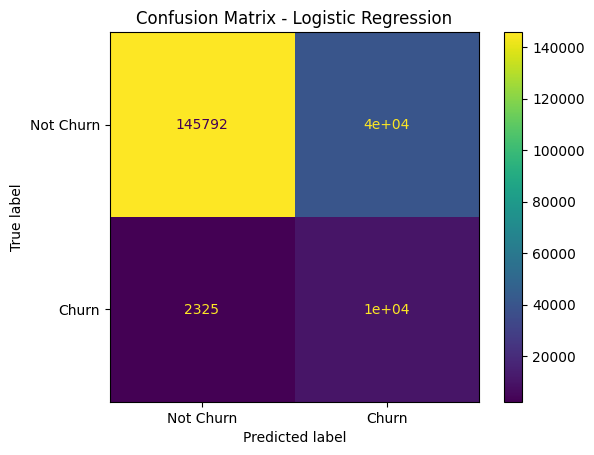

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=["Not Churn", "Churn"]
)

plt.title("Confusion Matrix - Logistic Regression")
plt.show()

## 13. Results and Observations

The Logistic Regression model achieved the following results on the test dataset:

- Accuracy: **78.64%**
- Churn Precision: **20.54%**
- Churn Recall: **81.68%**
- Churn F1-score: **32.83%**

The model achieved relatively high recall for the churn class, meaning it identified a large proportion of customers who actually churned.

However, churn precision was comparatively low, meaning that a considerable number of customers predicted as churners did not actually churn.

The results demonstrate the importance of evaluating multiple metrics when working with an imbalanced classification problem rather than relying on accuracy alone.

### Feature Selection Result

The feature-selection process reduced the number of features from **43 to 39** by removing highly correlated and redundant transaction-related features.

In [ ]:
final_feature_names = X_train_selected.columns.tolist()

print("Final number of features:", len(final_feature_names))
print("\nFinal features:")
for i, feature in enumerate(final_feature_names, 1):
    print(i, feature)

Final number of features: 39

Final features:
1 bd
2 transaction_count
3 cancel_count
4 avg_amount_paid
5 registration_year
6 registration_month
7 city_1.0
8 city_3.0
9 city_4.0
10 city_5.0
11 city_6.0
12 city_7.0
13 city_8.0
14 city_9.0
15 city_10.0
16 city_11.0
17 city_12.0
18 city_13.0
19 city_14.0
20 city_15.0
21 city_16.0
22 city_17.0
23 city_18.0
24 city_19.0
25 city_20.0
26 city_21.0
27 city_22.0
28 gender_female
29 gender_male
30 registered_via_3.0
31 registered_via_4.0
32 registered_via_7.0
33 registered_via_9.0
34 registered_via_13.0
35 age_group_18_30
36 age_group_31_45
37 age_group_46_60
38 age_group_60_plus
39 age_group_Under_18


# **FINAL**

In [ ]:
#preparing data for SVM


from sklearn.preprocessing import StandardScaler

# Create the scaler
scaler = StandardScaler()

# Learn scaling values from training data
X_train_scaled = scaler.fit_transform(X_train_selected)

# Apply the same scaling to test data
X_test_scaled = scaler.transform(X_test_selected)

print("Training data shape:", X_train_scaled.shape)
print("Testing data shape:", X_test_scaled.shape)
print("Missing values in training data:",
      X_train_scaled.isnan().sum() if hasattr(X_train_scaled, "isnan") else __import__("numpy").isnan(X_train_scaled).sum())
print("Missing values in testing data:",
      __import__("numpy").isnan(X_test_scaled).sum())


Training data shape: (794344, 39)
Testing data shape: (198587, 39)
Missing values in training data: 0
Missing values in testing data: 0


In [ ]:

from sklearn.utils.class_weight import compute_class_weight
import numpy as np

classes = np.unique(y_train)

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train
)

class_weights = dict(zip(classes, weights))

print("Class weights:", class_weights)


Class weights: {np.int64(0): np.float64(0.5341441995139644), np.int64(1): np.float64(7.821887862614964)}


In [ ]:
#train svm


from sklearn.svm import LinearSVC

svm_model = LinearSVC(
    class_weight="balanced",
    random_state=42,
    max_iter=3000
)

svm_model.fit(X_train_scaled, y_train)

print("SVM training completed!")


SVM training completed!


In [ ]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    classification_report,
    confusion_matrix
)

# Predict churn labels
svm_predictions = svm_model.predict(X_test_scaled)

# Calculate evaluation metrics
print("SVM MODEL PERFORMANCE")
print("-" * 35)

print("Accuracy:", accuracy_score(y_test, svm_predictions))
print("Precision:", precision_score(y_test, svm_predictions, zero_division=0))
print("Recall:", recall_score(y_test, svm_predictions, zero_division=0))
print("F1-Score:", f1_score(y_test, svm_predictions, zero_division=0))

# LinearSVC provides decision scores for ranking predictions
svm_scores = svm_model.decision_function(X_test_scaled)

print("ROC-AUC:", roc_auc_score(y_test, svm_scores))
print("PR-AUC:", average_precision_score(y_test, svm_scores))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, svm_predictions))

print("\nClassification Report:")
print(classification_report(y_test, svm_predictions, zero_division=0))


SVM MODEL PERFORMANCE
-----------------------------------
Accuracy: 0.7872519349202113
Precision: 0.20594965675057209
Recall: 0.8153458326768552
F1-Score: 0.32883763046275555
ROC-AUC: 0.8644075354584151
PR-AUC: 0.25112041141362107

Confusion Matrix:
[[145988  39905]
 [  2344  10350]]

Classification Report:
              precision    recall  f1-score   support

           0       0.98      0.79      0.87    185893
           1       0.21      0.82      0.33     12694

    accuracy                           0.79    198587
   macro avg       0.60      0.80      0.60    198587
weighted avg       0.93      0.79      0.84    198587



# SVM EVALUATION

In [ ]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    classification_report,
    confusion_matrix
)

# Predict churn labels
svm_predictions = svm_model.predict(X_test_scaled)

# Calculate evaluation metrics
print("SVM MODEL PERFORMANCE")
print("-" * 35)

print("Accuracy:", accuracy_score(y_test, svm_predictions))
print("Precision:", precision_score(y_test, svm_predictions, zero_division=0))
print("Recall:", recall_score(y_test, svm_predictions, zero_division=0))
print("F1-Score:", f1_score(y_test, svm_predictions, zero_division=0))

# LinearSVC provides decision scores for ranking predictions
svm_scores = svm_model.decision_function(X_test_scaled)

print("ROC-AUC:", roc_auc_score(y_test, svm_scores))
print("PR-AUC:", average_precision_score(y_test, svm_scores))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, svm_predictions))

print("\nClassification Report:")
print(classification_report(y_test, svm_predictions, zero_division=0))


SVM MODEL PERFORMANCE
-----------------------------------
Accuracy: 0.7872519349202113
Precision: 0.20594965675057209
Recall: 0.8153458326768552
F1-Score: 0.32883763046275555
ROC-AUC: 0.8644075354584151
PR-AUC: 0.25112041141362107

Confusion Matrix:
[[145988  39905]
 [  2344  10350]]

Classification Report:
              precision    recall  f1-score   support

           0       0.98      0.79      0.87    185893
           1       0.21      0.82      0.33     12694

    accuracy                           0.79    198587
   macro avg       0.60      0.80      0.60    198587
weighted avg       0.93      0.79      0.84    198587



       KKBOX CHURN PREDICTION — SVM
   Metric           Score
 Accuracy 0.7873 (78.73%)
Precision 0.2059 (20.59%)
   Recall 0.8153 (81.53%)
 F1-Score 0.3288 (32.88%)
  ROC-AUC 0.8644 (86.44%)
   PR-AUC 0.2511 (25.11%)


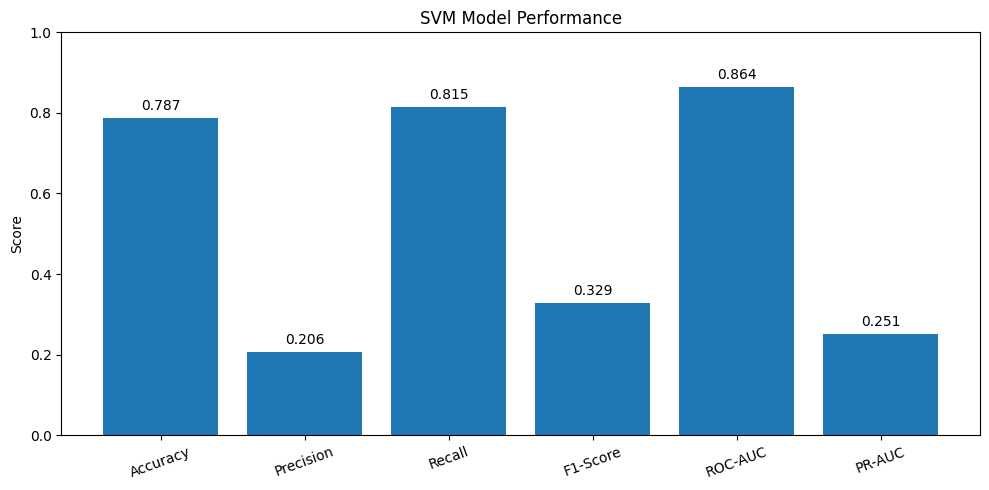

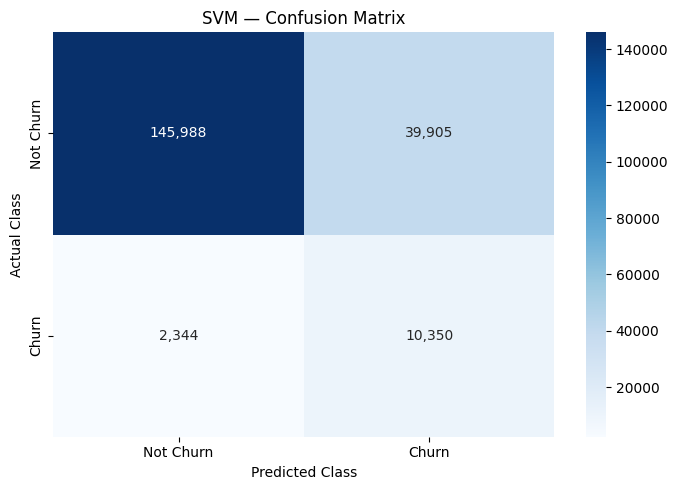

In [ ]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, average_precision_score,
    confusion_matrix
)

# Calculate performance metrics
svm_metrics = {
    "Accuracy": accuracy_score(y_test, svm_predictions),
    "Precision": precision_score(y_test, svm_predictions, zero_division=0),
    "Recall": recall_score(y_test, svm_predictions, zero_division=0),
    "F1-Score": f1_score(y_test, svm_predictions, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, svm_scores),
    "PR-AUC": average_precision_score(y_test, svm_scores)
}

# Display a clean metrics table
svm_results = pd.DataFrame(
    list(svm_metrics.items()),
    columns=["Metric", "Score"]
)

svm_results["Score"] = svm_results["Score"].map(
    lambda value: f"{value:.4f} ({value * 100:.2f}%)"
)

print("=" * 48)
print("       KKBOX CHURN PREDICTION — SVM")
print("=" * 48)
print(svm_results.to_string(index=False))

# Plot performance metrics
plt.figure(figsize=(10, 5))
metric_names = list(svm_metrics.keys())
metric_values = list(svm_metrics.values())

bars = plt.bar(metric_names, metric_values)

plt.ylim(0, 1)
plt.ylabel("Score")
plt.title("SVM Model Performance")
plt.xticks(rotation=20)

for bar, value in zip(bars, metric_values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.02,
        f"{value:.3f}",
        ha="center",
        fontsize=10
    )

plt.tight_layout()
plt.show()

# Plot confusion matrix
cm = confusion_matrix(y_test, svm_predictions)

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt=",",
    cmap="Blues",
    xticklabels=["Not Churn", "Churn"],
    yticklabels=["Not Churn", "Churn"]
)

plt.title("SVM — Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.tight_layout()
plt.show()


# **DECISION TREE**

In [ ]:

from sklearn.tree import DecisionTreeClassifier

dt_model = DecisionTreeClassifier(
    class_weight="balanced",
    max_depth=12,
    min_samples_leaf=100,
    random_state=42
)

dt_model.fit(X_train_selected, y_train)

print("Decision Tree training completed!")


Decision Tree training completed!


In [ ]:
#Evaluate the Decision Tree

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report
)

# Predict churn labels
dt_predictions = dt_model.predict(X_test_selected)

# Get probabilities for churn class
dt_scores = dt_model.predict_proba(X_test_selected)[:, 1]

# Calculate metrics
dt_metrics = {
    "Accuracy": accuracy_score(y_test, dt_predictions),
    "Precision": precision_score(y_test, dt_predictions, zero_division=0),
    "Recall": recall_score(y_test, dt_predictions, zero_division=0),
    "F1-Score": f1_score(y_test, dt_predictions, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, dt_scores),
    "PR-AUC": average_precision_score(y_test, dt_scores)
}

print("=" * 45)
print("     DECISION TREE PERFORMANCE")
print("=" * 45)

for metric, score in dt_metrics.items():
    print(f"{metric:<12}: {score:.4f} ({score * 100:.2f}%)")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, dt_predictions))

print("\nClassification Report:")
print(classification_report(
    y_test, dt_predictions, zero_division=0
))


     DECISION TREE PERFORMANCE
Accuracy    : 0.8198 (81.98%)
Precision   : 0.2503 (25.03%)
Recall      : 0.9116 (91.16%)
F1-Score    : 0.3928 (39.28%)
ROC-AUC     : 0.9345 (93.45%)
PR-AUC      : 0.5652 (56.52%)

Confusion Matrix:
[[151232  34661]
 [  1122  11572]]

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.81      0.89    185893
           1       0.25      0.91      0.39     12694

    accuracy                           0.82    198587
   macro avg       0.62      0.86      0.64    198587
weighted avg       0.95      0.82      0.86    198587



# **RANDOM FOREST **

In [ ]:

from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=150,
    max_depth=12,
    min_samples_leaf=100,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train_selected, y_train)

print("Random Forest training completed!")


Random Forest training completed!


In [ ]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report
)

# Predict churn labels
rf_predictions = rf_model.predict(X_test_selected)

# Get probabilities for the churn class (class 1)
rf_scores = rf_model.predict_proba(X_test_selected)[:, 1]

# Calculate performance metrics
rf_metrics = {
    "Accuracy": accuracy_score(y_test, rf_predictions),
    "Precision": precision_score(y_test, rf_predictions, zero_division=0),
    "Recall": recall_score(y_test, rf_predictions, zero_division=0),
    "F1-Score": f1_score(y_test, rf_predictions, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, rf_scores),
    "PR-AUC": average_precision_score(y_test, rf_scores)
}

print("=" * 45)
print("      RANDOM FOREST PERFORMANCE")
print("=" * 45)

for metric, score in rf_metrics.items():
    print(f"{metric:<12}: {score:.4f} ({score * 100:.2f}%)")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, rf_predictions))

print("\nClassification Report:")
print(classification_report(
    y_test, rf_predictions, zero_division=0
))


      RANDOM FOREST PERFORMANCE
Accuracy    : 0.7659 (76.59%)
Precision   : 0.2062 (20.62%)
Recall      : 0.9346 (93.46%)
F1-Score    : 0.3379 (33.79%)
ROC-AUC     : 0.9164 (91.64%)
PR-AUC      : 0.4174 (41.74%)

Confusion Matrix:
[[140234  45659]
 [   830  11864]]

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.75      0.86    185893
           1       0.21      0.93      0.34     12694

    accuracy                           0.77    198587
   macro avg       0.60      0.84      0.60    198587
weighted avg       0.94      0.77      0.82    198587



# **NEURAL NETWORK**

In [ ]:

from sklearn.neural_network import MLPClassifier

nn_model = MLPClassifier(
    hidden_layer_sizes=(64, 32),
    activation="relu",
    solver="adam",
    alpha=0.001,
    batch_size=2048,
    learning_rate_init=0.001,
    max_iter=30,
    early_stopping=True,
    validation_fraction=0.1,
    random_state=42,
    verbose=True
)

nn_model.fit(X_train_scaled, y_train)

print("\nNeural Network training completed!")


Iteration 1, loss = 0.25215535
Validation score: 0.936615
Iteration 2, loss = 0.17074267
Validation score: 0.937181
Iteration 3, loss = 0.16718043
Validation score: 0.938063
Iteration 4, loss = 0.16554491
Validation score: 0.938440
Iteration 5, loss = 0.16418178
Validation score: 0.937849
Iteration 6, loss = 0.16301451
Validation score: 0.938302
Iteration 7, loss = 0.16199027
Validation score: 0.938931
Iteration 8, loss = 0.16104714
Validation score: 0.939095
Iteration 9, loss = 0.16012327
Validation score: 0.939120
Iteration 10, loss = 0.15916271
Validation score: 0.939548
Iteration 11, loss = 0.15822838
Validation score: 0.939787
Iteration 12, loss = 0.15741724
Validation score: 0.939749
Iteration 13, loss = 0.15661646
Validation score: 0.940052
Iteration 14, loss = 0.15597643
Validation score: 0.940442
Iteration 15, loss = 0.15531402
Validation score: 0.940492
Iteration 16, loss = 0.15469078
Validation score: 0.942028
Iteration 17, loss = 0.15422157
Validation score: 0.943048
Iterat

/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (30) reached and the optimization hasn't converged yet.
  warnings.warn(


In [ ]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report
)

# Predict churn labels
nn_predictions = nn_model.predict(X_test_scaled)

# Probability of churn (class 1)
nn_scores = nn_model.predict_proba(X_test_scaled)[:, 1]

# Calculate performance metrics
nn_metrics = {
    "Accuracy": accuracy_score(y_test, nn_predictions),
    "Precision": precision_score(y_test, nn_predictions, zero_division=0),
    "Recall": recall_score(y_test, nn_predictions, zero_division=0),
    "F1-Score": f1_score(y_test, nn_predictions, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, nn_scores),
    "PR-AUC": average_precision_score(y_test, nn_scores)
}

print("=" * 45)
print("       NEURAL NETWORK PERFORMANCE")
print("=" * 45)

for metric, score in nn_metrics.items():
    print(f"{metric:<12}: {score:.4f} ({score * 100:.2f}%)")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, nn_predictions))

print("\nClassification Report:")
print(classification_report(
    y_test, nn_predictions, zero_division=0
))


       NEURAL NETWORK PERFORMANCE
Accuracy    : 0.9437 (94.37%)
Precision   : 0.6513 (65.13%)
Recall      : 0.2567 (25.67%)
F1-Score    : 0.3682 (36.82%)
ROC-AUC     : 0.9106 (91.06%)
PR-AUC      : 0.4624 (46.24%)

Confusion Matrix:
[[184149   1744]
 [  9436   3258]]

Classification Report:
              precision    recall  f1-score   support

           0       0.95      0.99      0.97    185893
           1       0.65      0.26      0.37     12694

    accuracy                           0.94    198587
   macro avg       0.80      0.62      0.67    198587
weighted avg       0.93      0.94      0.93    198587



# **THE ABOVE IS TRAINED ON IMBALANCED DATA **

In [ ]:
#Oversample the training data
from imblearn.over_sampling import RandomOverSampler

# Create the oversampler
oversampler = RandomOverSampler(random_state=42)

# Balance the scaled training data
X_train_nn_balanced, y_train_nn_balanced = oversampler.fit_resample(
    X_train_scaled, y_train
)

print("Original training shape:", X_train_scaled.shape)
print("Balanced training shape:", X_train_nn_balanced.shape)

print("\nClass distribution after oversampling:")
print(y_train_nn_balanced.value_counts())


Original training shape: (794344, 39)
Balanced training shape: (1487134, 39)

Class distribution after oversampling:
is_churn
0    743567
1    743567
Name: count, dtype: int64


In [ ]:
#training the improved neural network


from sklearn.neural_network import MLPClassifier

nn_balanced_model = MLPClassifier(
    hidden_layer_sizes=(64, 32),
    activation="relu",
    solver="adam",
    alpha=0.001,
    batch_size=2048,
    learning_rate_init=0.001,
    max_iter=40,
    early_stopping=True,
    validation_fraction=0.1,
    random_state=42,
    verbose=True
)

nn_balanced_model.fit(X_train_nn_balanced, y_train_nn_balanced)

print("\nBalanced Neural Network training completed!")


Iteration 1, loss = 0.42965929
Validation score: 0.819634
Iteration 2, loss = 0.38487947
Validation score: 0.829949
Iteration 3, loss = 0.37332468
Validation score: 0.833176
Iteration 4, loss = 0.36487401
Validation score: 0.837709
Iteration 5, loss = 0.35899529
Validation score: 0.840970
Iteration 6, loss = 0.35430737
Validation score: 0.841340
Iteration 7, loss = 0.35058013
Validation score: 0.843310
Iteration 8, loss = 0.34753919
Validation score: 0.844406
Iteration 9, loss = 0.34500747
Validation score: 0.846356
Iteration 10, loss = 0.34259444
Validation score: 0.846961
Iteration 11, loss = 0.34036063
Validation score: 0.849019
Iteration 12, loss = 0.33846715
Validation score: 0.849873
Iteration 13, loss = 0.33668856
Validation score: 0.850377
Iteration 14, loss = 0.33456750
Validation score: 0.851810
Iteration 15, loss = 0.33257188
Validation score: 0.852314
Iteration 16, loss = 0.33072699
Validation score: 0.853484
Iteration 17, loss = 0.32942376
Validation score: 0.854667
Iterat

/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (40) reached and the optimization hasn't converged yet.
  warnings.warn(


In [ ]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report
)

# Predict on the original test set
nn_balanced_predictions = nn_balanced_model.predict(X_test_scaled)

# Get churn probabilities
nn_balanced_scores = nn_balanced_model.predict_proba(X_test_scaled)[:, 1]

# Calculate metrics
nn_balanced_metrics = {
    "Accuracy": accuracy_score(y_test, nn_balanced_predictions),
    "Precision": precision_score(
        y_test, nn_balanced_predictions, zero_division=0
    ),
    "Recall": recall_score(
        y_test, nn_balanced_predictions, zero_division=0
    ),
    "F1-Score": f1_score(
        y_test, nn_balanced_predictions, zero_division=0
    ),
    "ROC-AUC": roc_auc_score(y_test, nn_balanced_scores),
    "PR-AUC": average_precision_score(y_test, nn_balanced_scores)
}

print("=" * 48)
print("   BALANCED NEURAL NETWORK PERFORMANCE")
print("=" * 48)

for metric, score in nn_balanced_metrics.items():
    print(f"{metric:<12}: {score:.4f} ({score * 100:.2f}%)")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, nn_balanced_predictions))

print("\nClassification Report:")
print(classification_report(
    y_test, nn_balanced_predictions, zero_division=0
))


   BALANCED NEURAL NETWORK PERFORMANCE
Accuracy    : 0.8073 (80.73%)
Precision   : 0.2346 (23.46%)
Recall      : 0.8907 (89.07%)
F1-Score    : 0.3714 (37.14%)
ROC-AUC     : 0.9220 (92.20%)
PR-AUC      : 0.4969 (49.69%)

Confusion Matrix:
[[149015  36878]
 [  1388  11306]]

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.80      0.89    185893
           1       0.23      0.89      0.37     12694

    accuracy                           0.81    198587
   macro avg       0.61      0.85      0.63    198587
weighted avg       0.94      0.81      0.85    198587



# CLUSTERING

In [ ]:
#K MEANS


from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Use a reproducible sample of training customers
X_cluster = X_train_scaled[:]

# Select a sample to make the initial experiment faster
import numpy as np

rng = np.random.RandomState(42)
sample_size = min(20000, X_cluster.shape[0])
sample_indices = rng.choice(
    X_cluster.shape[0],
    size=sample_size,
    replace=False
)

X_cluster_sample = X_cluster[sample_indices]

print("Full training feature shape:", X_cluster.shape)
print("Clustering sample shape:", X_cluster_sample.shape)
print("Missing values:", np.isnan(X_cluster_sample).sum())


Full training feature shape: (794344, 39)
Clustering sample shape: (20000, 39)
Missing values: 0


In [ ]:
#TRAIN K MEANS


from sklearn.cluster import KMeans

kmeans_model = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

kmeans_labels = kmeans_model.fit_predict(X_cluster_sample)

print("K-Means training completed!")
print("\nCluster sizes:")

import pandas as pd

cluster_sizes = pd.Series(kmeans_labels).value_counts().sort_index()
print(cluster_sizes)

print("\nInertia:", round(kmeans_model.inertia_, 2))


K-Means training completed!

Cluster sizes:
0     4439
1    11656
2     1036
3     2869
Name: count, dtype: int64

Inertia: 618031.45


In [ ]:

from sklearn.metrics import silhouette_score

silhouette = silhouette_score(
    X_cluster_sample,
    kmeans_labels
)

print("K-Means Silhouette Score:", round(silhouette, 4))


K-Means Silhouette Score: 0.3302


# **K medoids**

In [ ]:

%pip install scikit-learn-extra


In [ ]:

from sklearn_extra.cluster import KMedoids
from sklearn.metrics import silhouette_score

# Create the K-Medoids model
kmedoids_model = KMedoids(
    n_clusters=4,
    metric="euclidean",
    method="alternate",
    init="k-medoids++",
    random_state=42
)

# Train and assign cluster labels
kmedoids_labels = kmedoids_model.fit_predict(X_cluster_sample)

print("K-Medoids training completed!")

print("\nCluster sizes:")
print(
    pd.Series(kmedoids_labels)
    .value_counts()
    .sort_index()
)

# Evaluate clustering quality
kmedoids_silhouette = silhouette_score(
    X_cluster_sample,
    kmedoids_labels
)

print("\nK-Medoids Silhouette Score:",
      round(kmedoids_silhouette, 4))


K-Medoids training completed!

Cluster sizes:
0    15605
1     1542
2     2620
3      233
Name: count, dtype: int64

K-Medoids Silhouette Score: 0.3288


In [ ]:

# Get original features for the same sampled customers
cluster_analysis = X_train_final.iloc[sample_indices].copy()

# Reset row numbering
cluster_analysis = cluster_analysis.reset_index(drop=True)

# Add K-Means cluster labels
cluster_analysis["cluster"] = kmeans_labels

# Select features for analysis
features_to_analyze = [
    "bd",
    "transaction_count",
    "avg_amount_paid",
    "avg_plan_price",
    "avg_plan_days",
    "auto_renew_count",
    "cancel_count"
]

# Calculate average values for each cluster
cluster_summary = cluster_analysis.groupby("cluster")[
    features_to_analyze
].mean().round(2)

print("K-MEANS CUSTOMER SEGMENT SUMMARY")

display(cluster_summary)


K-MEANS CUSTOMER SEGMENT SUMMARY


,bd,transaction_count,avg_amount_paid,avg_plan_price,avg_plan_days,auto_renew_count,cancel_count
cluster,,,,,,,
0,24.98,17.20,187.91,181.42,38.47,14.06,0.35
1,27.87,15.56,116.36,116.25,29.84,15.20,0.25
2,26.76,6.62,198.29,198.98,39.99,3.45,0.11
3,38.69,19.53,189.46,179.41,38.69,18.64,0.33


In [ ]:

# Attach the actual churn labels for the sampled rows
cluster_analysis["is_churn"] = y_train.iloc[
    sample_indices
].reset_index(drop=True).values

# Calculate churn rate and customer count for each cluster
cluster_churn_summary = cluster_analysis.groupby("cluster").agg(
    customer_count=("is_churn", "size"),
    churned_customers=("is_churn", "sum"),
    churn_rate=("is_churn", "mean")
)

cluster_churn_summary["churn_rate"] = (
    cluster_churn_summary["churn_rate"] * 100
).round(2)

print("CHURN RATE BY K-MEANS CLUSTER")
display(cluster_churn_summary)


CHURN RATE BY K-MEANS CLUSTER


,customer_count,churned_customers,churn_rate
cluster,,,
0,4439,424,9.55
1,11656,470,4.03
2,1036,195,18.82
3,2869,185,6.45


# Combine **model**

In [ ]:

import numpy as np
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix
)

# Average the churn probabilities from both models
ensemble_scores = (
    dt_model.predict_proba(X_test_selected)[:, 1]
    + rf_model.predict_proba(X_test_selected)[:, 1]
) / 2

# Convert probabilities to class predictions
ensemble_predictions = (ensemble_scores >= 0.5).astype(int)

# Evaluate the ensemble
print("DECISION TREE + RANDOM FOREST ENSEMBLE")
print("-" * 45)
print("Accuracy:", round(accuracy_score(y_test, ensemble_predictions), 4))
print("Precision:", round(precision_score(y_test, ensemble_predictions, zero_division=0), 4))
print("Recall:", round(recall_score(y_test, ensemble_predictions, zero_division=0), 4))
print("F1-Score:", round(f1_score(y_test, ensemble_predictions, zero_division=0), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, ensemble_scores), 4))
print("PR-AUC:", round(average_precision_score(y_test, ensemble_scores), 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, ensemble_predictions))


DECISION TREE + RANDOM FOREST ENSEMBLE
---------------------------------------------
Accuracy: 0.8094
Precision: 0.2416
Recall: 0.9261
F1-Score: 0.3832
ROC-AUC: 0.9345
PR-AUC: 0.5036

Confusion Matrix:
[[148987  36906]
 [   938  11756]]


In [ ]:

# Get churn probabilities from both models
dt_nn_scores = (
    dt_model.predict_proba(X_test_selected)[:, 1]
    + nn_model.predict_proba(X_test_scaled)[:, 1]
) / 2

# Convert probabilities into final predictions
dt_nn_predictions = (dt_nn_scores >= 0.5).astype(int)

# Evaluate the combined model
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, average_precision_score,
    confusion_matrix, classification_report
)

print("Decision Tree + Neural Network (Soft Voting)")
print("-" * 50)
print("Accuracy:", round(accuracy_score(y_test, dt_nn_predictions), 4))
print("Precision:", round(precision_score(y_test, dt_nn_predictions, zero_division=0), 4))
print("Recall:", round(recall_score(y_test, dt_nn_predictions, zero_division=0), 4))
print("F1 Score:", round(f1_score(y_test, dt_nn_predictions, zero_division=0), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, dt_nn_scores), 4))
print("PR-AUC:", round(average_precision_score(y_test, dt_nn_scores), 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, dt_nn_predictions))

print("\nClassification Report:")
print(classification_report(y_test, dt_nn_predictions, zero_division=0))


Decision Tree + Neural Network (Soft Voting)
--------------------------------------------------
Accuracy: 0.9283
Precision: 0.4541
Recall: 0.5994
F1 Score: 0.5167
ROC-AUC: 0.9347
PR-AUC: 0.5323

Confusion Matrix:
[[176746   9147]
 [  5085   7609]]

Classification Report:
              precision    recall  f1-score   support

           0       0.97      0.95      0.96    185893
           1       0.45      0.60      0.52     12694

    accuracy                           0.93    198587
   macro avg       0.71      0.78      0.74    198587
weighted avg       0.94      0.93      0.93    198587



In [ ]:

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, average_precision_score
)
import pandas as pd

threshold_results = []

for threshold in [0.20, 0.25, 0.30, 0.35, 0.40, 0.45, 0.50, 0.55, 0.60]:
    predictions = (dt_nn_scores >= threshold).astype(int)

    threshold_results.append({
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions, zero_division=0),
        "Recall": recall_score(y_test, predictions, zero_division=0),
        "F1 Score": f1_score(y_test, predictions, zero_division=0)
    })

threshold_df = pd.DataFrame(threshold_results)

print(threshold_df.round(4).to_string(index=False))


 Threshold  Accuracy  Precision  Recall  F1 Score
      0.20    0.7785     0.2174  0.9484    0.3538
      0.25    0.8011     0.2345  0.9325    0.3747
      0.30    0.8222     0.2524  0.9081    0.3950
      0.35    0.8508     0.2827  0.8677    0.4265
      0.40    0.8818     0.3264  0.7987    0.4635
      0.45    0.9087     0.3839  0.7089    0.4981
      0.50    0.9283     0.4541  0.5994    0.5167
      0.55    0.9397     0.5304  0.4890    0.5089
      0.60    0.9446     0.5976  0.4077    0.4847


In [ ]:

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, average_precision_score
)
import pandas as pd

dt_scores = dt_model.predict_proba(X_test_selected)[:, 1]
nn_scores = nn_model.predict_proba(X_test_scaled)[:, 1]

weight_results = []

for dt_weight, nn_weight in [(0.6, 0.4), (0.7, 0.3), (0.8, 0.2)]:
    combined_scores = (
        dt_weight * dt_scores + nn_weight * nn_scores
    )

    predictions = (combined_scores >= 0.5).astype(int)

    weight_results.append({
        "DT Weight": dt_weight,
        "NN Weight": nn_weight,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions, zero_division=0),
        "Recall": recall_score(y_test, predictions, zero_division=0),
        "F1 Score": f1_score(y_test, predictions, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, combined_scores),
        "PR-AUC": average_precision_score(y_test, combined_scores)
    })

weight_df = pd.DataFrame(weight_results)
print(weight_df.round(4).to_string(index=False))


 DT Weight  NN Weight  Accuracy  Precision  Recall  F1 Score  ROC-AUC  PR-AUC
       0.6        0.4    0.9049     0.3745  0.7286    0.4948   0.9355  0.5403
       0.7        0.3    0.8751     0.3158  0.8172    0.4555   0.9359  0.5478
       0.8        0.2    0.8519     0.2835  0.8626    0.4268   0.9360  0.5549


In [ ]:
# check diff threshholds
from sklearn.metrics import precision_score, recall_score, f1_score
import pandas as pd

weighted_scores = 0.8 * dt_scores + 0.2 * nn_scores

threshold_results = []

for threshold in [0.30, 0.35, 0.40, 0.45, 0.50, 0.55, 0.60, 0.65, 0.70]:
    predictions = (weighted_scores >= threshold).astype(int)

    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision_score(y_test, predictions, zero_division=0),
        "Recall": recall_score(y_test, predictions, zero_division=0),
        "F1 Score": f1_score(y_test, predictions, zero_division=0)
    })

threshold_df = pd.DataFrame(threshold_results)
print(threshold_df.round(4).to_string(index=False))


 Threshold  Precision  Recall  F1 Score
      0.30     0.2225  0.9435    0.3601
      0.35     0.2346  0.9326    0.3750
      0.40     0.2485  0.9153    0.3909
      0.45     0.2585  0.8995    0.4016
      0.50     0.2835  0.8626    0.4268
      0.55     0.3137  0.8209    0.4539
      0.60     0.3571  0.7513    0.4841
      0.65     0.4050  0.6900    0.5104
      0.70     0.4818  0.5936    0.5319


In [ ]:

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, average_precision_score,
    confusion_matrix, classification_report
)

best_threshold = 0.70

best_ensemble_scores = 0.8 * dt_scores + 0.2 * nn_scores
best_ensemble_predictions = (
    best_ensemble_scores >= best_threshold
).astype(int)

print("Best Candidate: DT (80%) + NN (20%)")
print("Threshold:", best_threshold)
print("-" * 45)
print("Accuracy:", round(accuracy_score(y_test, best_ensemble_predictions), 4))
print("Precision:", round(precision_score(y_test, best_ensemble_predictions, zero_division=0), 4))
print("Recall:", round(recall_score(y_test, best_ensemble_predictions, zero_division=0), 4))
print("F1 Score:", round(f1_score(y_test, best_ensemble_predictions, zero_division=0), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, best_ensemble_scores), 4))
print("PR-AUC:", round(average_precision_score(y_test, best_ensemble_scores), 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, best_ensemble_predictions))

print("\nClassification Report:")
print(classification_report(y_test, best_ensemble_predictions, zero_division=0))


Best Candidate: DT (80%) + NN (20%)
Threshold: 0.7
---------------------------------------------
Accuracy: 0.9332
Precision: 0.4818
Recall: 0.5936
F1 Score: 0.5319
ROC-AUC: 0.936
PR-AUC: 0.5549

Confusion Matrix:
[[177788   8105]
 [  5159   7535]]

Classification Report:
              precision    recall  f1-score   support

           0       0.97      0.96      0.96    185893
           1       0.48      0.59      0.53     12694

    accuracy                           0.93    198587
   macro avg       0.73      0.77      0.75    198587
weighted avg       0.94      0.93      0.94    198587



In [ ]:

from sklearn.model_selection import train_test_split

# First, separate 15% for the final test set
X_remaining, X_test_new, y_remaining, y_test_new = train_test_split(
    X, y,
    test_size=0.15,
    random_state=42,
    stratify=y
)

# Split the remaining 85% into training and validation
# 15/85 = approximately 17.65% of the remaining data
X_train_new, X_val_new, y_train_new, y_val_new = train_test_split(
    X_remaining, y_remaining,
    test_size=0.1764705882,
    random_state=42,
    stratify=y_remaining
)

print("Training set:", X_train_new.shape, y_train_new.shape)
print("Validation set:", X_val_new.shape, y_val_new.shape)
print("Final test set:", X_test_new.shape, y_test_new.shape)

print("\nChurn rate in each set:")
print("Train:", round(y_train_new.mean() * 100, 2), "%")
print("Validation:", round(y_val_new.mean() * 100, 2), "%")
print("Test:", round(y_test_new.mean() * 100, 2), "%")


Training set: (695051, 12) (695051,)
Validation set: (148940, 12) (148940,)
Final test set: (148940, 12) (148940,)

Churn rate in each set:
Train: 6.39 %
Validation: 6.39 %
Test: 6.39 %


In [ ]:


# Make copies of the three datasets
X_train_clean = X_train_new.copy()
X_val_clean = X_val_new.copy()
X_test_clean = X_test_new.copy()

# Remove msno only if it exists
for df in [X_train_clean, X_val_clean, X_test_clean]:
    if "msno" in df.columns:
        df.drop(columns=["msno"], inplace=True)

# Identify categorical columns
categorical_cols = X_train_clean.select_dtypes(
    include=["object", "category"]
).columns.tolist()

print("Training columns:", X_train_clean.columns.tolist())
print("Categorical columns:", categorical_cols)
print("Training shape:", X_train_clean.shape)
print("Validation shape:", X_val_clean.shape)
print("Test shape:", X_test_clean.shape)


Training columns: ['city', 'bd', 'gender', 'registered_via', 'registration_init_time', 'transaction_count', 'total_amount_paid', 'auto_renew_count', 'cancel_count', 'avg_amount_paid', 'avg_plan_price', 'avg_plan_days']
Categorical columns: ['gender']
Training shape: (695051, 12)
Validation shape: (148940, 12)
Test shape: (148940, 12)


In [ ]:

# Convert category codes into categorical values
category_cols = ["city", "gender", "registered_via"]

for df in [X_train_clean, X_val_clean, X_test_clean]:
    for col in category_cols:
        df[col] = df[col].astype("string").fillna("Unknown")

    # Convert registration date into year and month
    df["registration_init_time"] = pd.to_datetime(
        df["registration_init_time"].astype("Int64").astype("string"),
        format="%Y%m%d",
        errors="coerce"
    )

    df["registration_year"] = df["registration_init_time"].dt.year
    df["registration_month"] = df["registration_init_time"].dt.month

    # Remove original date column after extracting features
    df.drop(columns=["registration_init_time"], inplace=True)

print("Updated training shape:", X_train_clean.shape)
print("\nData types:")
print(X_train_clean.dtypes)
print("\nMissing values in training data:")
print(X_train_clean.isnull().sum())


Updated training shape: (695051, 13)

Data types:
city                  string[python]
bd                           float64
gender                string[python]
registered_via        string[python]
transaction_count              int64
total_amount_paid            float64
auto_renew_count               int64
cancel_count                   int64
avg_amount_paid              float64
avg_plan_price               float64
avg_plan_days                float64
registration_year            float64
registration_month           float64
dtype: object

Missing values in training data:
city                      0
bd                    81116
gender                    0
registered_via            0
transaction_count         0
total_amount_paid         0
auto_renew_count          0
cancel_count              0
avg_amount_paid           0
avg_plan_price            0
avg_plan_days             0
registration_year     81116
registration_month    81116
dtype: int64


In [ ]:

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

# Define feature groups
categorical_cols = ["city", "gender", "registered_via"]

numeric_cols = [
    col for col in X_train_clean.columns
    if col not in categorical_cols
]

# Preprocess numeric features:
# Fill missing values using training medians, then scale
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Preprocess categorical features:
# Fill missing values, then one-hot encode
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine both preprocessing pipelines
preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_cols),
    ("categorical", categorical_pipeline, categorical_cols)
])

# Fit only on training data
X_train_processed = preprocessor.fit_transform(X_train_clean)

# Apply the same fitted preprocessing to validation and test
X_val_processed = preprocessor.transform(X_val_clean)
X_test_processed = preprocessor.transform(X_test_clean)

print("Training processed shape:", X_train_processed.shape)
print("Validation processed shape:", X_val_processed.shape)
print("Test processed shape:", X_test_processed.shape)

print("\nMissing values after preprocessing:")
print("Train:", pd.isna(X_train_processed).sum())
print("Validation:", pd.isna(X_val_processed).sum())
print("Test:", pd.isna(X_test_processed).sum())


Training processed shape: (695051, 41)
Validation processed shape: (148940, 41)
Test processed shape: (148940, 41)

Missing values after preprocessing:
Train: 0
Validation: 0
Test: 0


In [ ]:
#TRAINING FRESH DECISION TREE


from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, average_precision_score,
    confusion_matrix
)

# Train Decision Tree on the new training set
dt_new = DecisionTreeClassifier(
    class_weight="balanced",
    max_depth=12,
    min_samples_leaf=100,
    random_state=42
)

dt_new.fit(X_train_processed, y_train_new)

# Predict on validation data
dt_val_predictions = dt_new.predict(X_val_processed)
dt_val_scores = dt_new.predict_proba(X_val_processed)[:, 1]

# Evaluate validation performance
print("Decision Tree — Validation Results")
print("-" * 40)
print("Accuracy:", round(accuracy_score(y_val_new, dt_val_predictions), 4))
print("Precision:", round(precision_score(y_val_new, dt_val_predictions, zero_division=0), 4))
print("Recall:", round(recall_score(y_val_new, dt_val_predictions, zero_division=0), 4))
print("F1 Score:", round(f1_score(y_val_new, dt_val_predictions, zero_division=0), 4))
print("ROC-AUC:", round(roc_auc_score(y_val_new, dt_val_scores), 4))
print("PR-AUC:", round(average_precision_score(y_val_new, dt_val_scores), 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_val_new, dt_val_predictions))


Decision Tree — Validation Results
----------------------------------------
Accuracy: 0.8583
Precision: 0.3037
Recall: 0.9409
F1 Score: 0.4591
ROC-AUC: 0.9515
PR-AUC: 0.6096

Confusion Matrix:
[[118877  20542]
 [   563   8958]]


In [ ]:
#FRESH NN
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, average_precision_score,
    confusion_matrix
)

# Train Neural Network on the new training set
nn_new = MLPClassifier(
    hidden_layer_sizes=(64, 32),
    activation="relu",
    solver="adam",
    alpha=0.001,
    batch_size=2048,
    learning_rate_init=0.001,
    max_iter=40,
    early_stopping=True,
    validation_fraction=0.1,
    random_state=42
)

nn_new.fit(X_train_processed, y_train_new)

# Predict on validation data
nn_val_predictions = nn_new.predict(X_val_processed)
nn_val_scores = nn_new.predict_proba(X_val_processed)[:, 1]

# Evaluate validation performance
print("Neural Network — Validation Results")
print("-" * 40)
print("Accuracy:", round(accuracy_score(y_val_new, nn_val_predictions), 4))
print("Precision:", round(precision_score(y_val_new, nn_val_predictions, zero_division=0), 4))
print("Recall:", round(recall_score(y_val_new, nn_val_predictions, zero_division=0), 4))
print("F1 Score:", round(f1_score(y_val_new, nn_val_predictions, zero_division=0), 4))
print("ROC-AUC:", round(roc_auc_score(y_val_new, nn_val_scores), 4))
print("PR-AUC:", round(average_precision_score(y_val_new, nn_val_scores), 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_val_new, nn_val_predictions))


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (40) reached and the optimization hasn't converged yet.
  warnings.warn(


Neural Network — Validation Results
----------------------------------------
Accuracy: 0.9473
Precision: 0.6855
Recall: 0.3244
F1 Score: 0.4404
ROC-AUC: 0.9464
PR-AUC: 0.5792

Confusion Matrix:
[[138002   1417]
 [  6432   3089]]


In [ ]:
# COMBINE FRESH DT + NN
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, average_precision_score
)
import pandas as pd

# Get validation probabilities from both fresh models
dt_val_scores = dt_new.predict_proba(X_val_processed)[:, 1]
nn_val_scores = nn_new.predict_proba(X_val_processed)[:, 1]

# Test different voting weights
ensemble_results = []

for dt_weight, nn_weight in [(0.5, 0.5), (0.6, 0.4), (0.8, 0.2)]:
    combined_scores = (
        dt_weight * dt_val_scores
        + nn_weight * nn_val_scores
    )

    predictions = (combined_scores >= 0.5).astype(int)

    ensemble_results.append({
        "DT Weight": dt_weight,
        "NN Weight": nn_weight,
        "Accuracy": accuracy_score(y_val_new, predictions),
        "Precision": precision_score(y_val_new, predictions, zero_division=0),
        "Recall": recall_score(y_val_new, predictions, zero_division=0),
        "F1 Score": f1_score(y_val_new, predictions, zero_division=0),
        "ROC-AUC": roc_auc_score(y_val_new, combined_scores),
        "PR-AUC": average_precision_score(y_val_new, combined_scores)
    })

ensemble_df = pd.DataFrame(ensemble_results)
print(ensemble_df.round(4).to_string(index=False))


 DT Weight  NN Weight  Accuracy  Precision  Recall  F1 Score  ROC-AUC  PR-AUC
       0.5        0.5    0.9257     0.4509  0.7431    0.5612   0.9540  0.6133
       0.6        0.4    0.9032     0.3837  0.8474    0.5283   0.9542  0.6163
       0.8        0.2    0.8769     0.3324  0.9170    0.4879   0.9538  0.6204


In [ ]:

from sklearn.metrics import precision_score, recall_score, f1_score
import pandas as pd

# Equal-weight ensemble probabilities
ensemble_val_scores = (
    0.5 * dt_val_scores
    + 0.5 * nn_val_scores
)

threshold_results = []

for threshold in [0.30, 0.35, 0.40, 0.45, 0.50, 0.55, 0.60, 0.65, 0.70]:
    predictions = (ensemble_val_scores >= threshold).astype(int)

    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision_score(
            y_val_new, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_val_new, predictions, zero_division=0
        ),
        "F1 Score": f1_score(
            y_val_new, predictions, zero_division=0
        )
    })

threshold_df = pd.DataFrame(threshold_results)
print(threshold_df.round(4).to_string(index=False))


 Threshold  Precision  Recall  F1 Score
      0.30     0.3050  0.9464    0.4614
      0.35     0.3287  0.9233    0.4848
      0.40     0.3559  0.8887    0.5083
      0.45     0.3956  0.8283    0.5355
      0.50     0.4509  0.7431    0.5612
      0.55     0.5160  0.6431    0.5726
      0.60     0.5875  0.5299    0.5572
      0.65     0.6498  0.4278    0.5159
      0.70     0.7050  0.3494    0.4673


# FINAL COMBINED MODELS

In [ ]:

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, average_precision_score,
    confusion_matrix, classification_report
)

# Final ensemble probabilities on the untouched test set
dt_test_scores = dt_new.predict_proba(X_test_processed)[:, 1]
nn_test_scores = nn_new.predict_proba(X_test_processed)[:, 1]

final_test_scores = 0.5 * dt_test_scores + 0.5 * nn_test_scores

# Apply the threshold selected using validation data
final_threshold = 0.55
final_test_predictions = (
    final_test_scores >= final_threshold
).astype(int)

print("FINAL ENSEMBLE: Decision Tree + Neural Network")
print("DT Weight: 50% | NN Weight: 50%")
print("Threshold:", final_threshold)
print("-" * 50)

print("Accuracy:", round(accuracy_score(y_test_new, final_test_predictions), 4))
print("Precision:", round(precision_score(y_test_new, final_test_predictions, zero_division=0), 4))
print("Recall:", round(recall_score(y_test_new, final_test_predictions, zero_division=0), 4))
print("F1 Score:", round(f1_score(y_test_new, final_test_predictions, zero_division=0), 4))
print("ROC-AUC:", round(roc_auc_score(y_test_new, final_test_scores), 4))
print("PR-AUC:", round(average_precision_score(y_test_new, final_test_scores), 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test_new, final_test_predictions))

print("\nClassification Report:")
print(classification_report(y_test_new, final_test_predictions, zero_division=0))


FINAL ENSEMBLE: Decision Tree + Neural Network
DT Weight: 50% | NN Weight: 50%
Threshold: 0.55
--------------------------------------------------
Accuracy: 0.9379
Precision: 0.5113
Recall: 0.6355
F1 Score: 0.5667
ROC-AUC: 0.9536
PR-AUC: 0.611

Confusion Matrix:
[[133635   5784]
 [  3470   6051]]

Classification Report:
              precision    recall  f1-score   support

           0       0.97      0.96      0.97    139419
           1       0.51      0.64      0.57      9521

    accuracy                           0.94    148940
   macro avg       0.74      0.80      0.77    148940
weighted avg       0.95      0.94      0.94    148940



Top 15 Features for Churn Prediction
                            Feature  Importance
              numeric__cancel_count      0.4587
          numeric__auto_renew_count      0.3401
         numeric__transaction_count      0.0834
            numeric__avg_plan_price      0.0487
             numeric__avg_plan_days      0.0252
         numeric__total_amount_paid      0.0148
           numeric__avg_amount_paid      0.0107
        numeric__registration_month      0.0036
    categorical__registered_via_7.0      0.0036
         numeric__registration_year      0.0035
categorical__registered_via_Unknown      0.0026
                        numeric__bd      0.0023
              categorical__city_1.0      0.0010
    categorical__registered_via_9.0      0.0005
           categorical__gender_male      0.0003


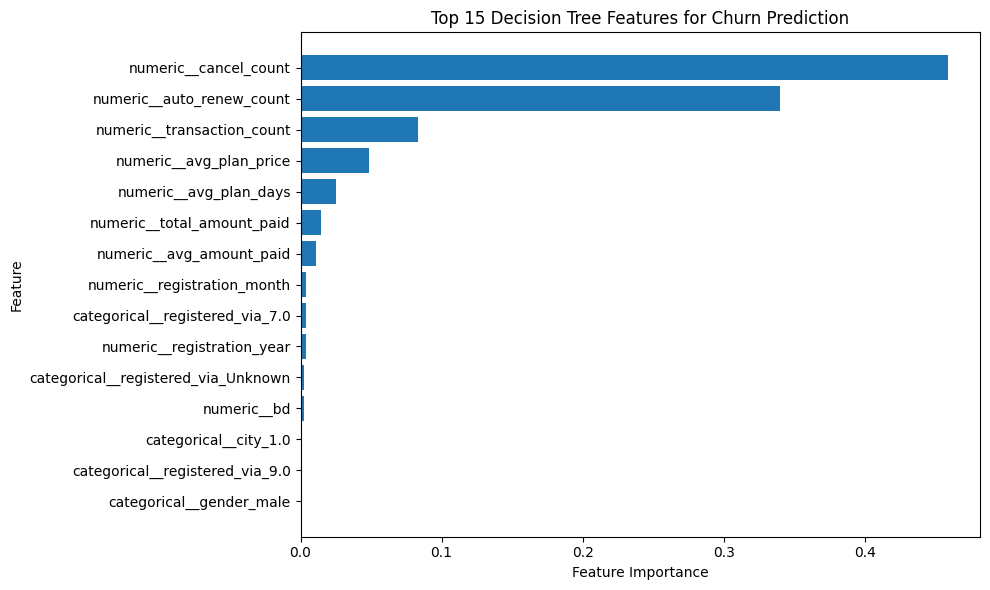

In [ ]:
#Calculate Decision Tree feature importance

import pandas as pd
import matplotlib.pyplot as plt

# Get the feature names after preprocessing
feature_names = preprocessor.get_feature_names_out()

# Extract feature importance from the trained Decision Tree
importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": dt_new.feature_importances_
})

# Sort features from most important to least important
importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
).reset_index(drop=True)

# Display the top 15 features
print("Top 15 Features for Churn Prediction")
print(importance_df.head(15).round(4).to_string(index=False))

# Plot the top 15 features
top_features = importance_df.head(15).sort_values("Importance")

plt.figure(figsize=(10, 6))
plt.barh(top_features["Feature"], top_features["Importance"])
plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title("Top 15 Decision Tree Features for Churn Prediction")
plt.tight_layout()
plt.show()


In [ ]:
# Combine target and transaction features for analysis
feature_check = train[["msno", "is_churn"]].merge(
    transaction_features,
    on="msno",
    how="left"
)

# Compare average feature values by churn status
print("Average transaction features by churn status:\n")

display(
    feature_check.groupby("is_churn")[
        [
            "transaction_count",
            "auto_renew_count",
            "cancel_count",
            "total_amount_paid",
            "avg_plan_days"
        ]
    ].mean().round(2)
)

# Check churn rate among customers with and without cancellations
print("\nChurn rate by cancellation history:\n")

display(
    feature_check.assign(
        has_cancellation=feature_check["cancel_count"] > 0
    ).groupby("has_cancellation")["is_churn"].agg(
        ["count", "mean"]
    ).rename(columns={"mean": "churn_rate"})
)

Average transaction features by churn status:



,transaction_count,auto_renew_count,cancel_count,total_amount_paid,avg_plan_days
is_churn,,,,,
0,16.35,15.31,0.26,2203.82,31.60
1,10.80,7.32,0.58,1748.08,61.79



Churn rate by cancellation history:



,count,churn_rate
has_cancellation,,
False,769186,0.044222
True,223745,0.131650


In [ ]:
print("Churn label counts:")
print(train["is_churn"].value_counts())

print("\nChurn label percentages:")
print(
    (train["is_churn"].value_counts(normalize=True) * 100)
    .round(2)
)

Churn label counts:
is_churn
0    929460
1     63471
Name: count, dtype: int64

Churn label percentages:
is_churn
0    93.61
1     6.39
Name: proportion, dtype: float64


# **AUTO ENCODER **

In [ ]:
#TRAIN THE AUTO ENCODER

import tensorflow as tf
from tensorflow.keras import layers, Model

# Input has 41 features
input_dim = X_train_processed.shape[1]

# Build the autoencoder
inputs = layers.Input(shape=(input_dim,))

# Encoder: compress 41 features into 16
x = layers.Dense(32, activation="relu")(inputs)
encoded = layers.Dense(16, activation="relu", name="encoded")(x)

# Decoder: reconstruct the original 41 features
x = layers.Dense(32, activation="relu")(encoded)
outputs = layers.Dense(input_dim, activation="linear")(x)

autoencoder = Model(inputs, outputs)

autoencoder.compile(
    optimizer="adam",
    loss="mse"
)

# Train to reconstruct the input
history = autoencoder.fit(
    X_train_processed.astype("float32"),
    X_train_processed.astype("float32"),
    validation_data=(
        X_val_processed.astype("float32"),
        X_val_processed.astype("float32")
    ),
    epochs=10,
    batch_size=2048,
    callbacks=[
        tf.keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=2,
            restore_best_weights=True
        )
    ],
    verbose=1
)

print("\nAutoencoder training completed!")
print("Original features:", input_dim)
print("Compressed features:", 16)

Epoch 1/10
340/340 ━━━━━━━━━━━━━━━━━━━━ 5s 12ms/step - loss: 0.1000 - val_loss: 0.0246
Epoch 2/10
340/340 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - loss: 0.0170 - val_loss: 0.0118
Epoch 3/10
340/340 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 0.0107 - val_loss: 0.0092
Epoch 4/10
340/340 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 0.0091 - val_loss: 0.0078
Epoch 5/10
340/340 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 0.0074 - val_loss: 0.0063
Epoch 6/10
340/340 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - loss: 0.0062 - val_loss: 0.0056
Epoch 7/10
340/340 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - loss: 0.0057 - val_loss: 0.0058
Epoch 8/10
340/340 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - loss: 0.0055 - val_loss: 0.0052
Epoch 9/10
340/340 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - loss: 0.0054 - val_loss: 0.0053
Epoch 10/10
340/340 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 0.0053 - val_loss: 0.0051

Autoencoder training completed!
Original features: 41
Compressed features: 16


In [ ]:
from tensorflow.keras import Model
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, average_precision_score
)

# Extract the 16 compressed features
encoder = Model(
    inputs=autoencoder.input,
    outputs=autoencoder.get_layer("encoded").output
)

X_train_encoded = encoder.predict(
    X_train_processed.astype("float32"),
    batch_size=4096,
    verbose=1
)

X_val_encoded = encoder.predict(
    X_val_processed.astype("float32"),
    batch_size=4096,
    verbose=1
)

print("Encoded training shape:", X_train_encoded.shape)
print("Encoded validation shape:", X_val_encoded.shape)

# Train a churn classifier on encoded features
ae_clf = DecisionTreeClassifier(
    class_weight="balanced",
    max_depth=12,
    min_samples_leaf=100,
    random_state=42
)

ae_clf.fit(X_train_encoded, y_train_new)

# Evaluate on validation data
ae_probs = ae_clf.predict_proba(X_val_encoded)[:, 1]
ae_preds = (ae_probs >= 0.5).astype(int)

print("\nAUTOENCODER + DECISION TREE — VALIDATION RESULTS")
print("Accuracy:", round(accuracy_score(y_val_new, ae_preds), 4))
print("Precision:", round(precision_score(y_val_new, ae_preds, zero_division=0), 4))
print("Recall:", round(recall_score(y_val_new, ae_preds, zero_division=0), 4))
print("F1 Score:", round(f1_score(y_val_new, ae_preds, zero_division=0), 4))
print("ROC-AUC:", round(roc_auc_score(y_val_new, ae_probs), 4))
print("PR-AUC:", round(average_precision_score(y_val_new, ae_probs), 4))

170/170 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
Encoded training shape: (695051, 16)
Encoded validation shape: (148940, 16)

AUTOENCODER + DECISION TREE — VALIDATION RESULTS
Accuracy: 0.8008
Precision: 0.2328
Recall: 0.9216
F1 Score: 0.3717
ROC-AUC: 0.9171
PR-AUC: 0.4657


# TRANSFORMER MODEL

In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, Model

# Build a small Transformer-style model for tabular data
inputs = layers.Input(shape=(X_train_processed.shape[1],))

# Treat each feature as a one-dimensional token
x = layers.Reshape((X_train_processed.shape[1], 1))(inputs)
x = layers.Dense(32)(x)

# Self-attention block
attention = layers.MultiHeadAttention(
    num_heads=4,
    key_dim=8
)(x, x)

x = layers.Add()([x, attention])
x = layers.LayerNormalization()(x)

# Feed-forward block
ff = layers.Dense(64, activation="relu")(x)
ff = layers.Dense(32)(ff)

x = layers.Add()([x, ff])
x = layers.LayerNormalization()(x)

# Pool features and predict churn probability
x = layers.GlobalAveragePooling1D()(x)
x = layers.Dense(32, activation="relu")(x)
x = layers.Dropout(0.2)(x)
outputs = layers.Dense(1, activation="sigmoid")(x)

transformer_model = Model(inputs, outputs)

transformer_model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy", tf.keras.metrics.AUC(name="auc")]
)

transformer_model.summary()

Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 41)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape (Reshape)   │ (None, 41, 1)     │          0 │ input_layer_1[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_3 (Dense)     │ (None, 41, 32)    │         64 │ reshape[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 41, 32)    │      4,224 │ dense_3[0][0],    │
│ (MultiHeadAttentio… │                   │            │ dense_3[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 41, 32)    │          0 │ dense_3[0][0],    │
│                     │                   │            │ multi_head_atten… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalization │ (None, 41, 32)    │         64 │ add[0][0]         │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_4 (Dense)     │ (None, 41, 64)    │      2,112 │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_5 (Dense)     │ (None, 41, 32)    │      2,080 │ dense_4[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_1 (Add)         │ (None, 41, 32)    │          0 │ layer_normalizat… │
│                     │                   │            │ dense_5[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 41, 32)    │         64 │ add_1[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 32)        │          0 │ layer_normalizat… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_6 (Dense)     │ (None, 32)        │      1,056 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 32)        │          0 │ dense_6[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_7 (Dense)     │ (None, 1)         │         33 │ dropout_1[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 9,697 (37.88 KB)

 Trainable params: 9,697 (37.88 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, average_precision_score
)
import numpy as np

# Calculate class weights using training data only
classes = np.array([0, 1])

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=np.asarray(y_train_new)
)

class_weights = {
    int(cls): float(weight)
    for cls, weight in zip(classes, weights)
}

print("Class weights:", class_weights)

# Train the Transformer
transformer_history = transformer_model.fit(
    X_train_processed.astype("float32"),
    np.asarray(y_train_new).astype("float32"),
    validation_data=(
        X_val_processed.astype("float32"),
        np.asarray(y_val_new).astype("float32")
    ),
    epochs=10,
    batch_size=2048,
    class_weight=class_weights,
    callbacks=[
        tf.keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=2,
            restore_best_weights=True
        )
    ],
    verbose=1
)

print("\nTransformer training completed!")

Class weights: {0: 0.5341434811611043, 1: 7.822041909563573}
Epoch 1/10
340/340 ━━━━━━━━━━━━━━━━━━━━ 315s 912ms/step - accuracy: 0.7087 - auc: 0.7187 - loss: 0.6115 - val_accuracy: 0.6839 - val_auc: 0.7815 - val_loss: 0.5648
Epoch 2/10
340/340 ━━━━━━━━━━━━━━━━━━━━ 313s 920ms/step - accuracy: 0.6874 - auc: 0.7879 - loss: 0.5500 - val_accuracy: 0.6814 - val_auc: 0.8055 - val_loss: 0.5504
Epoch 3/10
340/340 ━━━━━━━━━━━━━━━━━━━━ 313s 920ms/step - accuracy: 0.7159 - auc: 0.8147 - loss: 0.5212 - val_accuracy: 0.7305 - val_auc: 0.8391 - val_loss: 0.5266
Epoch 4/10
340/340 ━━━━━━━━━━━━━━━━━━━━ 311s 914ms/step - accuracy: 0.7426 - auc: 0.8379 - loss: 0.4937 - val_accuracy: 0.7761 - val_auc: 0.8486 - val_loss: 0.4645
Epoch 5/10
340/340 ━━━━━━━━━━━━━━━━━━━━ 322s 915ms/step - accuracy: 0.7520 - auc: 0.8555 - loss: 0.4697 - val_accuracy: 0.7252 - val_auc: 0.8711 - val_loss: 0.5101
Epoch 6/10
340/340 ━━━━━━━━━━━━━━━━━━━━ 321s 911ms/step - accuracy: 0.7606 - auc: 0.8662 - loss: 0.4534 - val_accuracy:

In [ ]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, average_precision_score
)
import numpy as np

# Predict churn probabilities on validation data
transformer_probs = transformer_model.predict(
    X_val_processed.astype("float32"),
    batch_size=4096,
    verbose=1
).ravel()

# Use 0.5 as the initial classification threshold
transformer_preds = (transformer_probs >= 0.5).astype(int)

print("TRANSFORMER — VALIDATION RESULTS")
print("Accuracy:", round(accuracy_score(y_val_new, transformer_preds), 4))
print("Precision:", round(precision_score(y_val_new, transformer_preds, zero_division=0), 4))
print("Recall:", round(recall_score(y_val_new, transformer_preds, zero_division=0), 4))
print("F1 Score:", round(f1_score(y_val_new, transformer_preds, zero_division=0), 4))
print("ROC-AUC:", round(roc_auc_score(y_val_new, transformer_probs), 4))
print("PR-AUC:", round(average_precision_score(y_val_new, transformer_probs), 4))

37/37 ━━━━━━━━━━━━━━━━━━━━ 20s 525ms/step
TRANSFORMER — VALIDATION RESULTS
Accuracy: 0.7761
Precision: 0.1898
Recall: 0.7657
F1 Score: 0.3042
ROC-AUC: 0.8486
PR-AUC: 0.2889


In [ ]:
import pandas as pd

comparison = pd.DataFrame([
    {
        "Model": "Decision Tree + Neural Network Ensemble",
        "Dataset": "Test",
        "Accuracy": 0.9379,
        "Precision": 0.5113,
        "Recall": 0.6355,
        "F1 Score": 0.5667,
        "ROC-AUC": 0.9536,
        "PR-AUC": 0.6110
    },
    {
        "Model": "Autoencoder + Decision Tree",
        "Dataset": "Validation",
        "Accuracy": 0.8036,
        "Precision": 0.2342,
        "Recall": 0.9124,
        "F1 Score": 0.3727,
        "ROC-AUC": 0.9168,
        "PR-AUC": 0.4647
    },
    {
        "Model": "Transformer",
        "Dataset": "Validation",
        "Accuracy": 0.7803,
        "Precision": 0.1933,
        "Recall": 0.7678,
        "F1 Score": 0.3088,
        "ROC-AUC": 0.8589,
        "PR-AUC": 0.3143
    }
])

display(comparison.round(4))

,Model,Dataset,Accuracy,Precision,Recall,F1 Score,ROC-AUC,PR-AUC
0,Decision Tree + Neural Network Ensemble,Test,0.9379,0.5113,0.6355,0.5667,0.9536,0.6110
1,Autoencoder + Decision Tree,Validation,0.8036,0.2342,0.9124,0.3727,0.9168,0.4647
2,Transformer,Validation,0.7803,0.1933,0.7678,0.3088,0.8589,0.3143


# Final Results: KKBox Churn Prediction

This section summarizes the customer clustering experiments, the best combined classification model, and the deep-learning experiments using an Autoencoder and a Transformer.

The objective is to identify churn-prone customers, understand customer groups, and compare different approaches to churn prediction.

### 1. Customer Clustering: K-Means vs K-Medoids

K-Means groups customers around cluster centroids, while K-Medoids groups them around representative real data points called medoids.

Both methods were explored for customer segmentation. Their recorded silhouette scores were:

- K-Means: 0.3302
- K-Medoids: 0.3288

The scores are close, suggesting similar clustering separation in the evaluated feature space.

In [ ]:
import pandas as pd
from IPython.display import display

clustering_results = pd.DataFrame({
    "Algorithm": ["K-Means", "K-Medoids"],
    "Silhouette Score": [0.3302, 0.3288]
})

display(clustering_results)

,Algorithm,Silhouette Score
0,K-Means,0.3302
1,K-Medoids,0.3288


### 2. Best Classification Model: Decision Tree + Neural Network

The ensemble combines the predicted probabilities of a Decision Tree and a Neural Network using equal weights (50% each).

A classification threshold of 0.55 was selected using validation data. The final ensemble was then evaluated on the held-out test set.

**Recorded test results:**
- Accuracy: 93.79%
- Precision: 51.13%
- Recall: 63.55%
- F1-score: 56.67%
- ROC-AUC: 95.36%
- PR-AUC: 61.10%

ROC-AUC measures how well the model ranks churned customers above non-churned customers. F1-score balances precision and recall.

In [ ]:
ensemble_results = pd.DataFrame({
    "Metric": [
        "Accuracy", "Precision", "Recall",
        "F1 Score", "ROC-AUC", "PR-AUC"
    ],
    "Test Score": [
        0.9379, 0.5113, 0.6355,
        0.5667, 0.9536, 0.6110
    ]
})

display(ensemble_results)

,Metric,Test Score
0,Accuracy,0.9379
1,Precision,0.5113
2,Recall,0.6355
3,F1 Score,0.5667
4,ROC-AUC,0.9536
5,PR-AUC,0.6110


### 3. Autoencoder + Decision Tree

The Autoencoder compresses 41 input features into 16 encoded features and learns to reconstruct the original inputs. A Decision Tree then uses these compressed features to predict churn.

The reconstruction model reached a validation loss of 0.0053. The classifier achieved a validation F1-score of 37.27%.

This experiment demonstrates dimensionality reduction, but the recorded classifier did not outperform the existing ensemble in F1-score. The results use different evaluation splits, so a fair comparison would require the same evaluation protocol.

In [ ]:
autoencoder_results = pd.DataFrame({
    "Metric": [
        "Original Features",
        "Encoded Features",
        "Validation Reconstruction Loss",
        "Validation Accuracy",
        "Validation F1 Score",
        "Validation ROC-AUC",
        "Validation PR-AUC"
    ],
    "Result": [
        41, 16, 0.0053, 0.8036,
        0.3727, 0.9168, 0.4647
    ]
})

display(autoencoder_results)

,Metric,Result
0,Original Features,41.0000
1,Encoded Features,16.0000
2,Validation Reconstruction Loss,0.0053
3,Validation Accuracy,0.8036
4,Validation F1 Score,0.3727
5,Validation ROC-AUC,0.9168
6,Validation PR-AUC,0.4647


### 4. Transformer-Based Churn Prediction

A Transformer-style neural network uses self-attention to learn relationships between the input features. The model includes multi-head attention, residual connections, layer normalization, and a classification output.

Class weights were used to address the imbalance between churned and non-churned customers. Training stopped after seven epochs through early stopping.

**Validation results:**
- Accuracy: 78.03%
- Precision: 19.33%
- Recall: 76.78%
- F1-score: 30.88%
- ROC-AUC: 85.89%
- PR-AUC: 31.43%

In this experiment, the Transformer did not demonstrate better F1-score than the recorded ensemble.

In [ ]:
transformer_results = pd.DataFrame({
    "Metric": [
        "Accuracy", "Precision", "Recall",
        "F1 Score", "ROC-AUC", "PR-AUC"
    ],
    "Validation Score": [
        0.7803, 0.1933, 0.7678,
        0.3088, 0.8589, 0.3143
    ]
})

display(transformer_results)

,Metric,Validation Score
0,Accuracy,0.7803
1,Precision,0.1933
2,Recall,0.7678
3,F1 Score,0.3088
4,ROC-AUC,0.8589
5,PR-AUC,0.3143


In [ ]:
final_comparison = pd.DataFrame([
    {
        "Model": "Decision Tree + Neural Network",
        "Split": "Test",
        "Accuracy": 0.9379,
        "Precision": 0.5113,
        "Recall": 0.6355,
        "F1 Score": 0.5667,
        "ROC-AUC": 0.9536,
        "PR-AUC": 0.6110
    },
    {
        "Model": "Autoencoder + Decision Tree",
        "Split": "Validation",
        "Accuracy": 0.8036,
        "Precision": 0.2342,
        "Recall": 0.9124,
        "F1 Score": 0.3727,
        "ROC-AUC": 0.9168,
        "PR-AUC": 0.4647
    },
    {
        "Model": "Transformer",
        "Split": "Validation",
        "Accuracy": 0.7803,
        "Precision": 0.1933,
        "Recall": 0.7678,
        "F1 Score": 0.3088,
        "ROC-AUC": 0.8589,
        "PR-AUC": 0.3143
    }
])

display(final_comparison.round(4))

,Model,Split,Accuracy,Precision,Recall,F1 Score,ROC-AUC,PR-AUC
0,Decision Tree + Neural Network,Test,0.9379,0.5113,0.6355,0.5667,0.9536,0.6110
1,Autoencoder + Decision Tree,Validation,0.8036,0.2342,0.9124,0.3727,0.9168,0.4647
2,Transformer,Validation,0.7803,0.1933,0.7678,0.3088,0.8589,0.3143


# **TESTING ON NEW DATASET**

In [ ]:
required_objects = [
    "preprocessor",
    "dt_new",
    "nn_new",
    "X_train_clean"
]

for name in required_objects:
    print(f"{name}: {'Available' if name in globals() else 'Missing'}")

preprocessor: Available
dt_new: Available
nn_new: Available
X_train_clean: Available


In [ ]:
import os

# Google Drive dataset locations
base_dir = "/content/drive/MyDrive/kkbox_aiml/kkbox_v2"
data_dir = os.path.join(base_dir, "data", "churn_comp_refresh")

# Create extraction folders
os.makedirs(data_dir, exist_ok=True)

# Extract V2 files
!7z x -y "{data_dir}/transactions_v2.csv.7z" -o"{data_dir}"
!7z x -y "{data_dir}/train_v2.csv.7z" -o"{data_dir}"
!7z x -y "{data_dir}/user_logs_v2.csv.7z" -o"{data_dir}"

# Extract members file
!7z x -y "{base_dir}/members_v3.csv.7z" -o"{base_dir}"

print("Extraction completed!")


7-Zip 23.01 (x64) : Copyright (c) 1999-2023 Igor Pavlov : 2023-06-20
 64-bit locale=en_US.UTF-8 Threads:2 OPEN_MAX:1048576

Scanning the drive for archives:
  0M Scan /content/drive/MyDrive/kkbox_aiml/kkbox_v2/data/churn_comp_refresh/                                                                             1 file, 48850410 bytes (47 MiB)

Extracting archive: /content/drive/MyDrive/kkbox_aiml/kkbox_v2/data/churn_comp_refresh/transactions_v2.csv.7z
--
Path = /content/drive/MyDrive/kkbox_aiml/kkbox_v2/data/churn_comp_refresh/transactions_v2.csv.7z
Type = 7z
Physical Size = 48850410
Headers Size = 194
Method = LZMA2:24
Solid = -
Blocks = 1

  0%      1%      8%     15%     22%     30%     38%     46%     53%     61%     69%     77%     86%

In [ ]:
import pandas as pd

base = "/content/drive/MyDrive/kkbox_aiml/kkbox_v2"
data = f"{base}/data/churn_comp_refresh/data/churn_comp_refresh"

train_v2 = pd.read_csv(f"{data}/train_v2.csv")
members_v3 = pd.read_csv(f"{base}/members_v3.csv")
transactions_v2 = pd.read_csv(f"{data}/transactions_v2.csv")

print("ALL DATASETS LOADED SUCCESSFULLY!")
print("Train:", train_v2.shape)
print("Members:", members_v3.shape)
print("Transactions:", transactions_v2.shape)

ALL DATASETS LOADED SUCCESSFULLY!
Train: (970960, 2)
Members: (6769473, 6)
Transactions: (1431009, 9)


In [ ]:
import os

for root, dirs, files in os.walk("/content/kkbox_v2"):
    for file in files:
        print(file, f"— {os.path.getsize(os.path.join(root, file)) / (1024**2):.1f} MB")

In [ ]:
import pandas as pd
import os

# Correct folder containing the extracted dataset
data_dir = "/content/drive/MyDrive/kkbox_aiml/kkbox_v2/data/churn_comp_refresh/data/churn_comp_refresh"

# Load training labels
train_v2 = pd.read_csv(
    os.path.join(data_dir, "train_v2.csv")
)

# Load only 5 rows to inspect the other files
members_sample = pd.read_csv(
    "/content/drive/MyDrive/kkbox_aiml/kkbox_v2/members_v3.csv",
    nrows=5
)

transactions_sample = pd.read_csv(
    os.path.join(data_dir, "transactions_v2.csv"),
    nrows=5
)

print("TRAIN V2")
print("Shape:", train_v2.shape)
print(train_v2.head())
print("Columns:", train_v2.columns.tolist())

print("\nMEMBERS V3 SAMPLE")
print(members_sample)
print("Columns:", members_sample.columns.tolist())

print("\nTRANSACTIONS V2 SAMPLE")
print(transactions_sample)
print("Columns:", transactions_sample.columns.tolist())

TRAIN V2
Shape: (970960, 2)
                                           msno  is_churn
0  ugx0CjOMzazClkFzU2xasmDZaoIqOUAZPsH1q0teWCg=         1
1  f/NmvEzHfhINFEYZTR05prUdr+E+3+oewvweYz9cCQE=         1
2  zLo9f73nGGT1p21ltZC3ChiRnAVvgibMyazbCxvWPcg=         1
3  8iF/+8HY8lJKFrTc7iR9ZYGCG2Ecrogbc2Vy5YhsfhQ=         1
4  K6fja4+jmoZ5xG6BypqX80Uw/XKpMgrEMdG2edFOxnA=         1
Columns: ['msno', 'is_churn']

MEMBERS V3 SAMPLE
                                           msno  city  bd  gender  \
0  Rb9UwLQTrxzBVwCB6+bCcSQWZ9JiNLC9dXtM1oEsZA8=     1   0     NaN   
1  +tJonkh+O1CA796Fm5X60UMOtB6POHAwPjbTRVl/EuU=     1   0     NaN   
2  cV358ssn7a0f7jZOwGNWS07wCKVqxyiImJUX6xcIwKw=     1   0     NaN   
3  9bzDeJP6sQodK73K5CBlJ6fgIQzPeLnRl0p5B77XP+g=     1   0     NaN   
4  WFLY3s7z4EZsieHCt63XrsdtfTEmJ+2PnnKLH5GY4Tk=     6  32  female   

   registered_via  registration_init_time  
0              11                20110911  
1               7                20110914  
2              11           

In [ ]:
import pandas as pd
import numpy as np
import os

data_dir = "/content/drive/MyDrive/kkbox_aiml/kkbox_v2/data/churn_comp_refresh/data/churn_comp_refresh"

# Load transaction data
transactions_v2 = pd.read_csv(
    os.path.join(data_dir, "transactions_v2.csv")
)

print("Transactions loaded:", transactions_v2.shape)

# Create customer-level transaction features
transaction_features_v2 = transactions_v2.groupby("msno").agg(
    transaction_count=("msno", "size"),
    total_amount_paid=("actual_amount_paid", "sum"),
    auto_renew_count=("is_auto_renew", "sum"),
    cancel_count=("is_cancel", "sum"),
    avg_amount_paid=("actual_amount_paid", "mean"),
    avg_plan_price=("plan_list_price", "mean"),
    avg_plan_days=("payment_plan_days", "mean")
).reset_index()

print("Customer transaction features:", transaction_features_v2.shape)
display(transaction_features_v2.head())

Transactions loaded: (1431009, 9)
Customer transaction features: (1197050, 8)


,msno,transaction_count,total_amount_paid,auto_renew_count,cancel_count,avg_amount_paid,avg_plan_price,avg_plan_days
0,+++IZseRRiQS9aaSkH6cMYU6bGDcxUieAi/tH67sC5s=,1,1599,0,0,1599.0,1599.0,395.0
1,+++hVY1rZox/33YtvDgmKA2Frg/2qhkz12B9ylCvh8o=,1,99,1,0,99.0,99.0,30.0
2,+++l/EXNMLTijfLBa8p2TUVVVp2aFGSuUI/h7mLmthw=,2,298,2,0,149.0,149.0,30.0
3,+++snpr7pmobhLKUgSHTv/mpkqgBT0tQJ0zQj6qKrqc=,1,149,1,0,149.0,149.0,30.0
4,++/9R3sX37CjxbY/AaGvbwr3QkwElKBCtSvVzhCBDOk=,1,149,1,0,149.0,149.0,30.0


In [ ]:
# Load all member information
members_v2 = pd.read_csv(
   "/content/drive/MyDrive/kkbox_aiml/kkbox_v2/members_v3.csv"
)

# Merge churn labels with membership information
new_data_v2 = train_v2.merge(
    members_v2,
    on="msno",
    how="left"
)

# Add transaction features
new_data_v2 = new_data_v2.merge(
    transaction_features_v2,
    on="msno",
    how="left"
)

# Customers without transaction records get zero transaction counts/amounts
transaction_cols = [
    "transaction_count",
    "total_amount_paid",
    "auto_renew_count",
    "cancel_count",
    "avg_amount_paid",
    "avg_plan_price",
    "avg_plan_days"
]

new_data_v2[transaction_cols] = new_data_v2[transaction_cols].fillna(0)

print("New dataset shape:", new_data_v2.shape)
print("\nMissing values in key columns:")
print(new_data_v2[
    ["city", "bd", "gender", "registered_via",
     "registration_init_time"] + transaction_cols
].isna().sum())

display(new_data_v2.head())

New dataset shape: (970960, 14)

Missing values in key columns:
city                      109993
bd                        109993
gender                    582055
registered_via            109993
registration_init_time    109993
transaction_count              0
total_amount_paid              0
auto_renew_count               0
cancel_count                   0
avg_amount_paid                0
avg_plan_price                 0
avg_plan_days                  0
dtype: int64


,msno,is_churn,city,bd,gender,registered_via,registration_init_time,transaction_count,total_amount_paid,auto_renew_count,cancel_count,avg_amount_paid,avg_plan_price,avg_plan_days
0,ugx0CjOMzazClkFzU2xasmDZaoIqOUAZPsH1q0teWCg=,1,5.0,28.0,male,3.0,20131223.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,f/NmvEzHfhINFEYZTR05prUdr+E+3+oewvweYz9cCQE=,1,13.0,20.0,male,3.0,20131223.0,1.0,180.0,0.0,0.0,180.0,180.0,30.0
2,zLo9f73nGGT1p21ltZC3ChiRnAVvgibMyazbCxvWPcg=,1,13.0,18.0,male,3.0,20131227.0,2.0,300.0,0.0,0.0,150.0,150.0,75.0
3,8iF/+8HY8lJKFrTc7iR9ZYGCG2Ecrogbc2Vy5YhsfhQ=,1,1.0,0.0,NaN,7.0,20140109.0,10.0,1490.0,10.0,0.0,149.0,149.0,30.0
4,K6fja4+jmoZ5xG6BypqX80Uw/XKpMgrEMdG2edFOxnA=,1,13.0,35.0,female,7.0,20140125.0,8.0,792.0,8.0,1.0,99.0,99.0,30.0


In [ ]:
# Prepare features exactly like the original model
new_features_v2 = new_data_v2.drop(
    columns=["msno", "is_churn"]
).copy()

# Convert registration date into year and month
new_features_v2["registration_init_time"] = pd.to_datetime(
    new_features_v2["registration_init_time"].astype("Int64").astype("string"),
    format="%Y%m%d",
    errors="coerce"
)
new_features_v2["registration_year"] = (
    new_features_v2["registration_init_time"].dt.year
)
new_features_v2["registration_month"] = (
    new_features_v2["registration_init_time"].dt.month
)
new_features_v2.drop(columns=["registration_init_time"], inplace=True)

# Match categorical types used during training
for col in ["city", "gender", "registered_via"]:
    new_features_v2[col] = new_features_v2[col].astype("string").fillna("Unknown")

# Apply the EXISTING preprocessing pipeline
new_processed_v2 = preprocessor.transform(new_features_v2)

# Existing Decision Tree + Neural Network probabilities
dt_prob_v2 = dt_new.predict_proba(new_processed_v2)[:, 1]
nn_prob_v2 = nn_new.predict_proba(new_processed_v2)[:, 1]

# Existing 50/50 ensemble and threshold
ensemble_prob_v2 = (dt_prob_v2 + nn_prob_v2) / 2
predictions_v2 = (ensemble_prob_v2 >= 0.55).astype(int)

# Summarize predictions
print("Customers evaluated:", len(predictions_v2))
print("Predicted churn:", int(predictions_v2.sum()))
print("Predicted non-churn:", int((predictions_v2 == 0).sum()))
print("Predicted churn rate:", f"{predictions_v2.mean():.2%}")

Customers evaluated: 970960
Predicted churn: 253138
Predicted non-churn: 717822
Predicted churn rate: 26.07%


In [ ]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, average_precision_score,
    confusion_matrix, classification_report
)

y_true_v2 = new_data_v2["is_churn"]

print("NEW KKBOX V2 — DT + NN ENSEMBLE")
print("-" * 45)
print(f"Accuracy:  {accuracy_score(y_true_v2, predictions_v2):.4f}")
print(f"Precision: {precision_score(y_true_v2, predictions_v2, zero_division=0):.4f}")
print(f"Recall:    {recall_score(y_true_v2, predictions_v2, zero_division=0):.4f}")
print(f"F1 Score:  {f1_score(y_true_v2, predictions_v2, zero_division=0):.4f}")
print(f"ROC-AUC:   {roc_auc_score(y_true_v2, ensemble_prob_v2):.4f}")
print(f"PR-AUC:    {average_precision_score(y_true_v2, ensemble_prob_v2):.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_true_v2, predictions_v2))

print("\nClassification Report:")
print(classification_report(y_true_v2, predictions_v2, zero_division=0))

NEW KKBOX V2 — DT + NN ENSEMBLE
---------------------------------------------
Accuracy:  0.7972
Precision: 0.2835
Recall:    0.8219
F1 Score:  0.4216
ROC-AUC:   0.8061
PR-AUC:    0.4699

Confusion Matrix:
[[702266 181364]
 [ 15556  71774]]

Classification Report:
              precision    recall  f1-score   support

           0       0.98      0.79      0.88    883630
           1       0.28      0.82      0.42     87330

    accuracy                           0.80    970960
   macro avg       0.63      0.81      0.65    970960
weighted avg       0.92      0.80      0.84    970960



In [ ]:
comparison_v2 = pd.DataFrame([{
    "Model": "Decision Tree + Neural Network",
    "Dataset": "KKBox V2",
    "Customers": len(y_true_v2),
    "Accuracy": accuracy_score(y_true_v2, predictions_v2),
    "Precision": precision_score(y_true_v2, predictions_v2),
    "Recall": recall_score(y_true_v2, predictions_v2),
    "F1 Score": f1_score(y_true_v2, predictions_v2),
    "ROC-AUC": roc_auc_score(y_true_v2, ensemble_prob_v2),
    "PR-AUC": average_precision_score(y_true_v2, ensemble_prob_v2)
}])

display(comparison_v2.round(4))

,Model,Dataset,Customers,Accuracy,Precision,Recall,F1 Score,ROC-AUC,PR-AUC
0,Decision Tree + Neural Network,KKBox V2,970960,0.7972,0.2835,0.8219,0.4216,0.8061,0.4699


In [ ]:
final_comparison = pd.DataFrame([
    {
        "Dataset": "Original Test Set",
        "Customers": 148940,
        "Accuracy": 0.9379,
        "Precision": 0.5113,
        "Recall": 0.6355,
        "F1 Score": 0.5667,
        "ROC-AUC": 0.9536,
        "PR-AUC": 0.6110
    },
    {
        "Dataset": "KKBox V2",
        "Customers": 970960,
        "Accuracy": 0.7972,
        "Precision": 0.2835,
        "Recall": 0.8219,
        "F1 Score": 0.4216,
        "ROC-AUC": 0.8061,
        "PR-AUC": 0.4699
    }
])

display(final_comparison.round(4))

,Dataset,Customers,Accuracy,Precision,Recall,F1 Score,ROC-AUC,PR-AUC
0,Original Test Set,148940,0.9379,0.5113,0.6355,0.5667,0.9536,0.6110
1,KKBox V2,970960,0.7972,0.2835,0.8219,0.4216,0.8061,0.4699


In [ ]:
import joblib
import os

path = "/content/drive/MyDrive/kkbox_aiml/saved_models"
os.makedirs(path, exist_ok=True)

joblib.dump(preprocessor, f"{path}/preprocessor.pkl")
joblib.dump(dt_new, f"{path}/dt_new.pkl")
joblib.dump(nn_new, f"{path}/nn_new.pkl")

print("Models saved permanently!")

Models saved permanently!


In [ ]:
# ==========================================================
# EXPLAINABLE AI (XAI) - SETUP
# ==========================================================

!pip -q install shap lime

import shap
import lime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from lime.lime_tabular import LimeTabularExplainer

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, average_precision_score,
    confusion_matrix, roc_curve, precision_recall_curve
)

# Use existing V2 processed data and predictions
X_xai = new_processed_v2
y_xai = new_data_v2["is_churn"].astype(int).to_numpy()

prob_xai = np.asarray(ensemble_prob_v2).ravel()
pred_xai = np.asarray(predictions_v2).ravel()

# Get feature names from the existing preprocessing pipeline
feature_names = list(preprocessor.get_feature_names_out())

# Select small samples to make explanations faster
rng = np.random.default_rng(42)

shap_indices = rng.choice(
    X_xai.shape[0], min(300, X_xai.shape[0]), replace=False
)

lime_indices = rng.choice(
    X_xai.shape[0], min(1000, X_xai.shape[0]), replace=False
)

X_shap = X_xai[shap_indices]
X_shap = X_shap.toarray() if hasattr(X_shap, "toarray") else np.asarray(X_shap)

X_lime = X_xai[lime_indices]
X_lime = X_lime.toarray() if hasattr(X_lime, "toarray") else np.asarray(X_lime)

print("=" * 60)
print("       EXPLAINABLE AI - INITIALIZATION COMPLETE")
print("=" * 60)
print("Total customers:", len(y_xai))
print("Processed features:", len(feature_names))
print("SHAP sample:", X_shap.shape)
print("LIME sample:", X_lime.shape)
print("Existing models reused: Decision Tree + Neural Network")
print("=" * 60)

       EXPLAINABLE AI - INITIALIZATION COMPLETE
Total customers: 970960
Processed features: 41
SHAP sample: (300, 41)
LIME sample: (1000, 41)
Existing models reused: Decision Tree + Neural Network


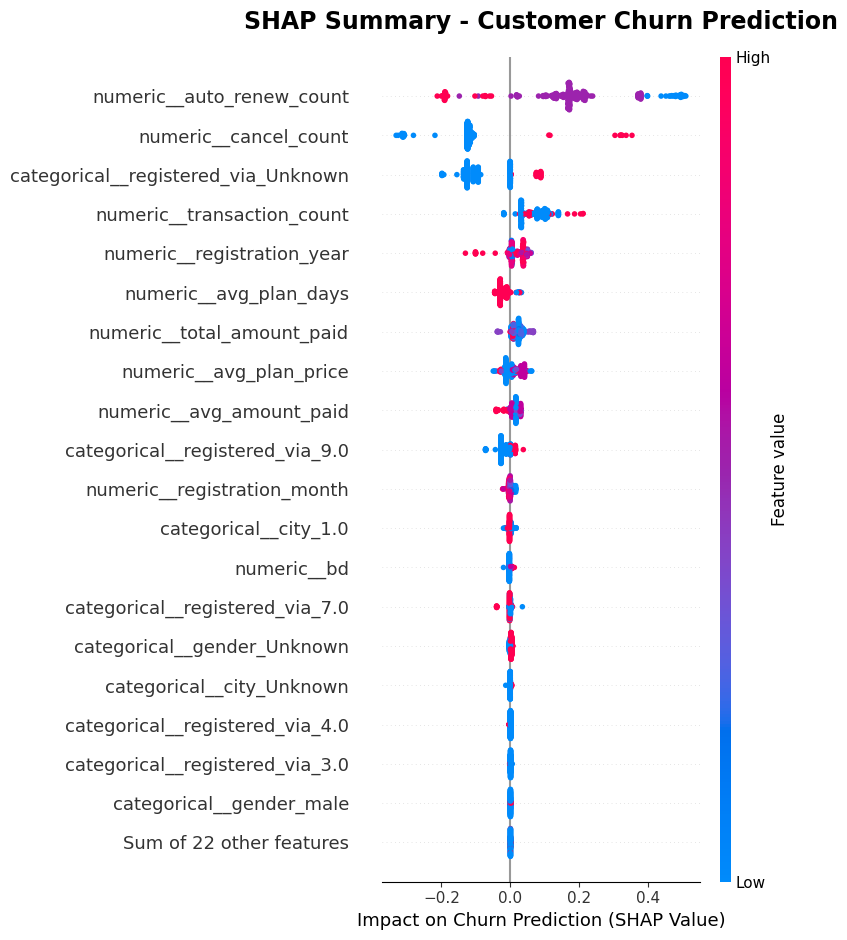

Actual feature names successfully attached!
Top features: ['numeric__bd', 'numeric__transaction_count', 'numeric__total_amount_paid', 'numeric__auto_renew_count', 'numeric__cancel_count']


In [ ]:
# ==========================================================
# SHAP 1 - GLOBAL FEATURE IMPACT (NAMED FEATURES)
# ==========================================================

# Calculate SHAP values
shap_explainer = shap.TreeExplainer(dt_new)
raw_shap = shap_explainer.shap_values(X_shap)

# Extract churn class (class 1)
if isinstance(raw_shap, list):
    values = raw_shap[1]
elif np.ndim(raw_shap) == 3:
    values = raw_shap[:, :, 1]
else:
    values = raw_shap

# Get expected/base value for churn class
base = shap_explainer.expected_value

if isinstance(base, (list, np.ndarray)):
    base = np.asarray(base).flatten()[-1]

# IMPORTANT: Attach actual feature names
shap_churn = shap.Explanation(
    values=values,
    base_values=np.full(len(X_shap), float(base)),
    data=X_shap,
    feature_names=feature_names
)

# Create professional SHAP summary plot
plt.figure(figsize=(13, 9))

shap.plots.beeswarm(
    shap_churn,
    max_display=20,
    show=False
)

plt.title(
    "SHAP Summary - Customer Churn Prediction",
    fontsize=17,
    fontweight="bold",
    pad=20
)

plt.xlabel("Impact on Churn Prediction (SHAP Value)")
plt.tight_layout()
plt.show()

print("Actual feature names successfully attached!")
print("Top features:", feature_names[:5])

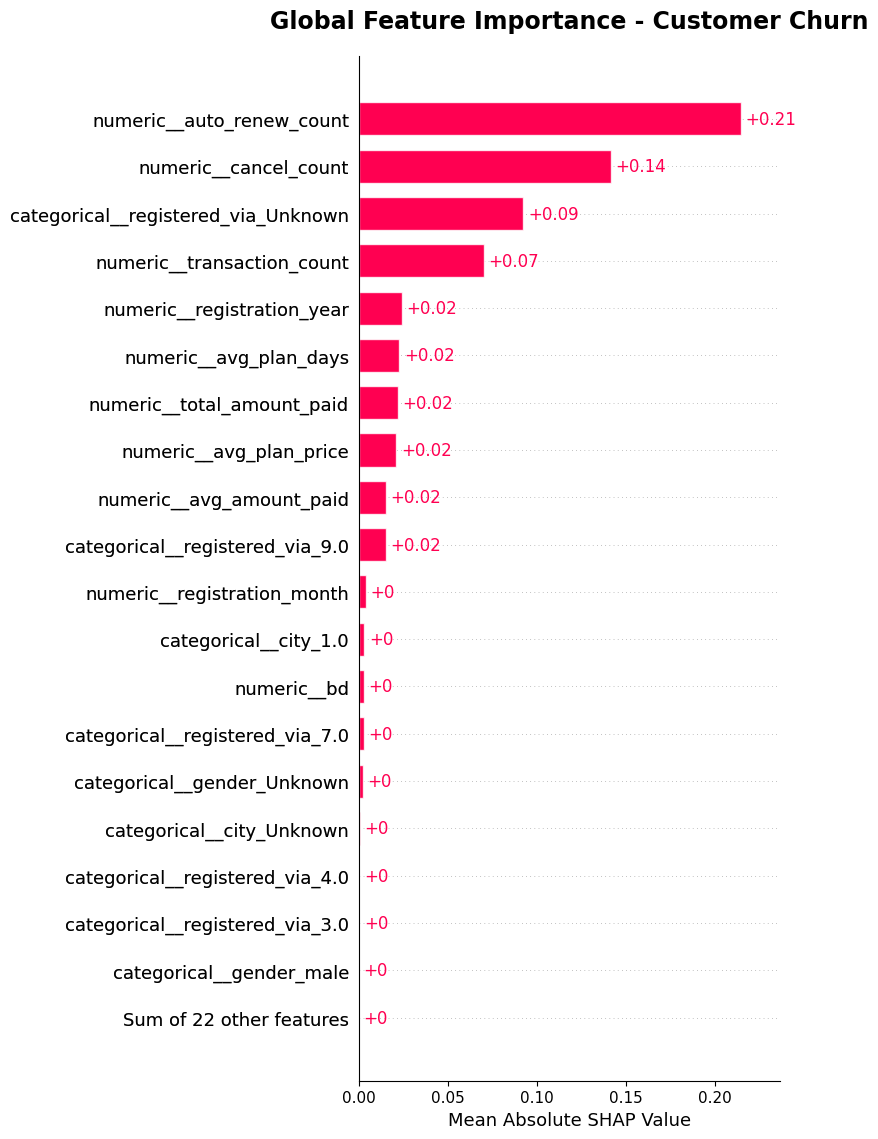

Feature,Mean SHAP Impact
numeric__auto_renew_count,0.21432
numeric__cancel_count,0.14124
categorical__registered_via_Unknown,0.09232
numeric__transaction_count,0.07025
numeric__registration_year,0.02422
numeric__avg_plan_days,0.02282
numeric__total_amount_paid,0.02179
numeric__avg_plan_price,0.02107
numeric__avg_amount_paid,0.01535
categorical__registered_via_9.0,0.01528



GRAPH INTERPRETATION:

1. Each horizontal bar represents one feature.
2. Longer bars mean greater average influence on predictions.
3. Shorter bars mean lower average influence.
4. The ranking is based on the average absolute SHAP value
   across the selected customers.

WHAT THIS TELLS US:
The graph identifies the features the Decision Tree relies
on most across the sampled customer population.

Unlike the summary plot, this graph does not show whether
a feature increases or decreases churn predictions.
It only measures the average magnitude of its influence.



In [ ]:
# ==========================================================
# SHAP 2 - GLOBAL FEATURE IMPORTANCE
# ==========================================================

plt.figure(figsize=(13, 9))

shap.plots.bar(
    shap_churn,
    max_display=20,
    show=False
)

plt.title(
    "Global Feature Importance - Customer Churn",
    fontsize=17,
    fontweight="bold",
    pad=20
)

plt.xlabel("Mean Absolute SHAP Value")
plt.tight_layout()
plt.show()

# Display actual feature names and importance scores
importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Mean SHAP Impact": np.abs(shap_churn.values).mean(axis=0)
}).sort_values("Mean SHAP Impact", ascending=False)

display(
    importance_df.head(20).style
    .format({"Mean SHAP Impact": "{:.5f}"})
    .background_gradient(subset=["Mean SHAP Impact"], cmap="Blues")
    .hide(axis="index")
)

print("""
GRAPH INTERPRETATION:

1. Each horizontal bar represents one feature.
2. Longer bars mean greater average influence on predictions.
3. Shorter bars mean lower average influence.
4. The ranking is based on the average absolute SHAP value
   across the selected customers.

WHAT THIS TELLS US:
The graph identifies the features the Decision Tree relies
on most across the sampled customer population.

Unlike the summary plot, this graph does not show whether
a feature increases or decreases churn predictions.
It only measures the average magnitude of its influence.
""")

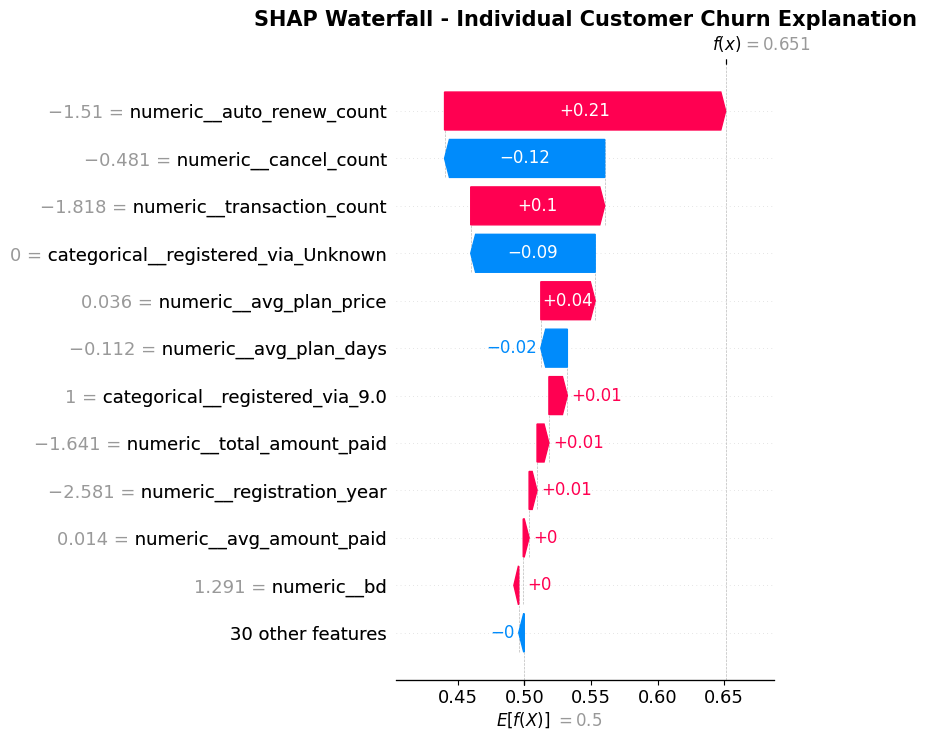


HOW TO UNDERSTAND THE WATERFALL GRAPH

1. BASE VALUE:
   This is the model's average output over the background
   data used by the SHAP explainer.

2. RED BARS:
   Features pushing this customer's model output towards
   the churn class.

3. BLUE BARS:
   Features pushing the output away from the churn class.

4. BAR LENGTH:
   Longer bars represent a larger contribution.

5. FINAL OUTPUT:
   The result after adding all feature contributions
   to the base value.

PROJECT INTERPRETATION:
This graph gives us a detailed explanation of one customer.
It identifies the features that influenced the Decision Tree
to produce its particular churn prediction.

A red bar does not mean the customer definitely will churn.
It means that the feature pushed the model output towards
the churn class.

Actual customer label: 0
Decision Tree prediction: 1


In [ ]:
# ==========================================================
# SHAP 3 - INDIVIDUAL CUSTOMER EXPLANATION (WATERFALL)
# ==========================================================

# Select one customer from our SHAP sample
customer_shap = shap_churn[0]

plt.figure(figsize=(12, 8))

shap.plots.waterfall(
    customer_shap,
    max_display=12,
    show=False
)

plt.title(
    "SHAP Waterfall - Individual Customer Churn Explanation",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

print("\n" + "=" * 65)
print("HOW TO UNDERSTAND THE WATERFALL GRAPH")
print("=" * 65)

print("""
1. BASE VALUE:
   This is the model's average output over the background
   data used by the SHAP explainer.

2. RED BARS:
   Features pushing this customer's model output towards
   the churn class.

3. BLUE BARS:
   Features pushing the output away from the churn class.

4. BAR LENGTH:
   Longer bars represent a larger contribution.

5. FINAL OUTPUT:
   The result after adding all feature contributions
   to the base value.

PROJECT INTERPRETATION:
This graph gives us a detailed explanation of one customer.
It identifies the features that influenced the Decision Tree
to produce its particular churn prediction.

A red bar does not mean the customer definitely will churn.
It means that the feature pushed the model output towards
the churn class.
""")

print("Actual customer label:", int(y_xai[shap_indices[0]]))
print("Decision Tree prediction:",
      int(dt_new.predict(X_shap[0:1])[0]))

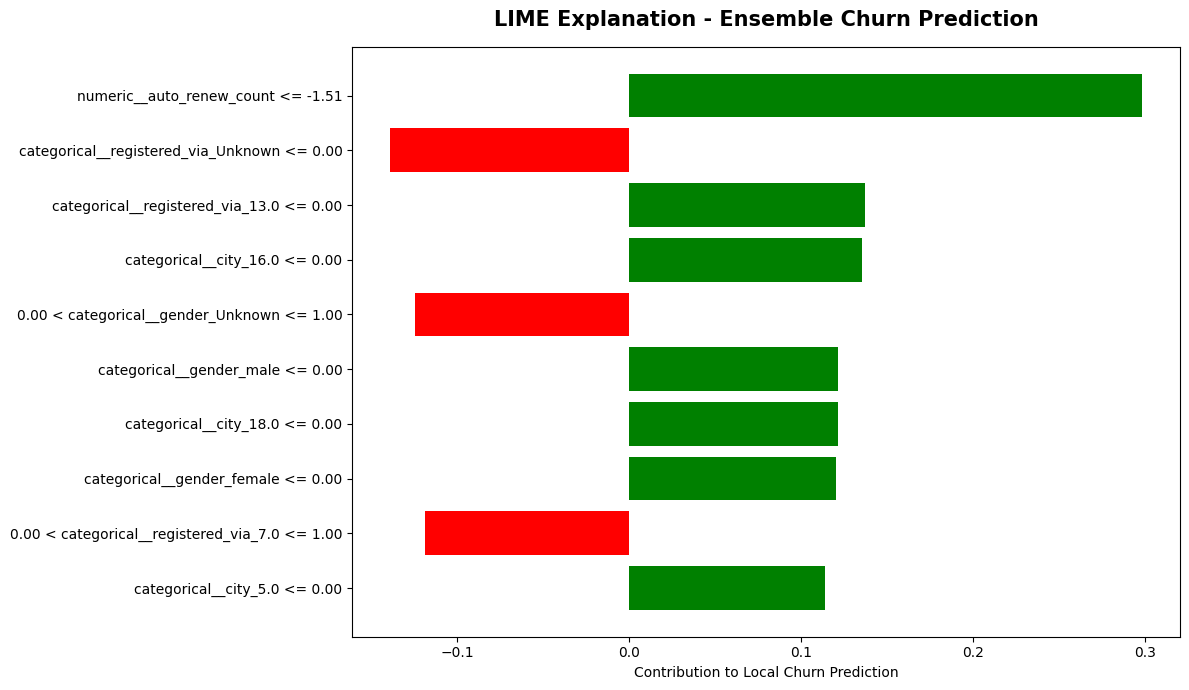


HOW TO UNDERSTAND THE LIME GRAPH

1. EACH BAR:
   Represents one feature influencing the selected customer's
   local prediction.

2. GREEN BARS:
   Features supporting the class being explained (Churn).

3. RED BARS:
   Features opposing the Churn explanation.

4. BAR LENGTH:
   Shows the strength of the feature's contribution in
   LIME's local approximation.

5. CUSTOMER PROBABILITY:
   The combined model's estimated probability of churn.

PROJECT INTERPRETATION:
LIME creates a simplified local explanation around one
customer. It shows which feature conditions support or
oppose the ensemble's churn prediction.

LIME is a local approximation. Its contributions explain
the selected prediction, not the entire model.

Ensemble churn probability: 0.2238
Ensemble predicted class: NO CHURN

Top LIME contributions:
numeric__auto_renew_count <= -1.51: +0.2982
categorical__registered_via_Unknown <= 0.00: -0.1389
categorical__registered_via_13.0 <= 0.00: +0.1371
categorical__city_16.0 <= 0.00

In [ ]:
# ==========================================================
# LIME - LOCAL EXPLANATION OF THE ENSEMBLE MODEL
# ==========================================================

def ensemble_predict_proba(X):
    dt_probability = dt_new.predict_proba(X)[:, 1]
    nn_probability = nn_new.predict_proba(X)[:, 1]

    churn_probability = (dt_probability + nn_probability) / 2

    return np.column_stack([
        1 - churn_probability,
        churn_probability
    ])


# Create LIME explainer
lime_explainer = LimeTabularExplainer(
    training_data=X_lime,
    feature_names=feature_names,
    class_names=["No Churn", "Churn"],
    mode="classification",
    discretize_continuous=True,
    random_state=42
)

# Select one customer
customer_lime = X_lime[0]

# Generate local explanation
lime_result = lime_explainer.explain_instance(
    customer_lime,
    ensemble_predict_proba,
    num_features=10,
    labels=(1,)
)

# Display explanation
fig = lime_result.as_pyplot_figure(label=1)
fig.set_size_inches(12, 7)

plt.title(
    "LIME Explanation - Ensemble Churn Prediction",
    fontsize=15,
    fontweight="bold",
    pad=15
)

plt.xlabel("Contribution to Local Churn Prediction")
plt.tight_layout()
plt.show()

# Display the customer's probability
customer_probability = ensemble_predict_proba(
    customer_lime.reshape(1, -1)
)[0, 1]

print("\n" + "=" * 65)
print("HOW TO UNDERSTAND THE LIME GRAPH")
print("=" * 65)

print("""
1. EACH BAR:
   Represents one feature influencing the selected customer's
   local prediction.

2. GREEN BARS:
   Features supporting the class being explained (Churn).

3. RED BARS:
   Features opposing the Churn explanation.

4. BAR LENGTH:
   Shows the strength of the feature's contribution in
   LIME's local approximation.

5. CUSTOMER PROBABILITY:
   The combined model's estimated probability of churn.

PROJECT INTERPRETATION:
LIME creates a simplified local explanation around one
customer. It shows which feature conditions support or
oppose the ensemble's churn prediction.

LIME is a local approximation. Its contributions explain
the selected prediction, not the entire model.
""")

print("Ensemble churn probability:", f"{customer_probability:.4f}")
print("Ensemble predicted class:",
      "CHURN" if customer_probability >= 0.55 else "NO CHURN")

print("\nTop LIME contributions:")
for feature, contribution in lime_result.as_list(label=1):
    print(f"{feature}: {contribution:+.4f}")

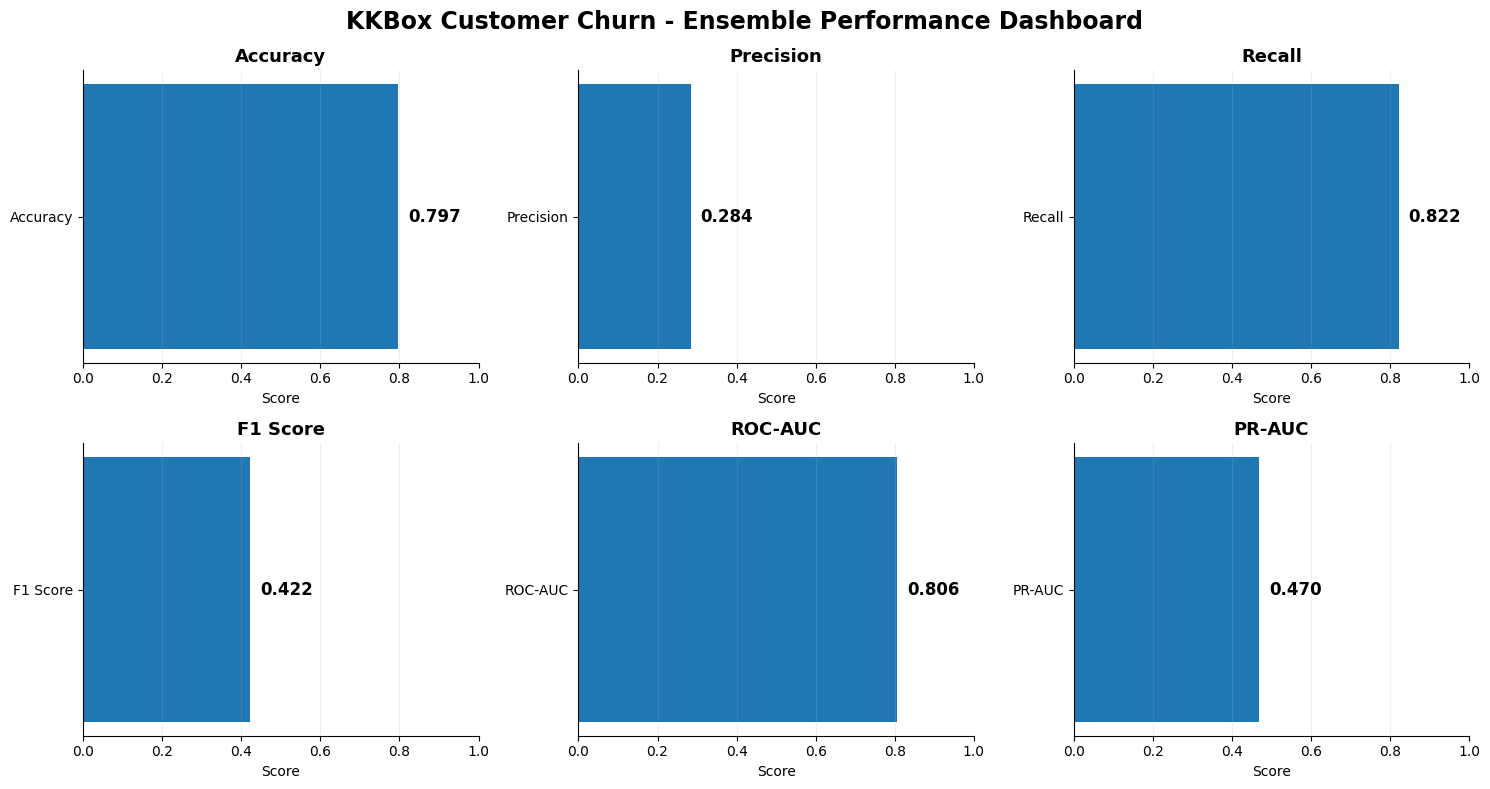


          PERFORMANCE METRICS - INTERPRETATION

ACCURACY  : 0.7972
Out of all customers, this is the proportion classified
correctly by the model.

PRECISION : 0.2835
Out of all customers predicted as churners, this is the
proportion who actually churned.

RECALL    : 0.8219
Out of all actual churners, this is the proportion
successfully identified by the model.

F1 SCORE  : 0.4216
This balances precision and recall into one score.

ROC-AUC   : 0.8061
Measures how well the model separates churners from
non-churners across different classification thresholds.

PR-AUC    : 0.4699
Summarizes the precision-recall trade-off and is especially
useful when churners are much less common.

BUSINESS INTERPRETATION:
High recall means the model catches more potential churners.
However, low precision means more non-churners may also
receive retention offers.

The business must balance missed churners against the
cost of contacting customers who would not have churned.



In [ ]:
# ==========================================================
# XAI - MODEL PERFORMANCE DASHBOARD
# ==========================================================

metrics = {
    "Accuracy": accuracy_score(y_xai, pred_xai),
    "Precision": precision_score(y_xai, pred_xai, zero_division=0),
    "Recall": recall_score(y_xai, pred_xai, zero_division=0),
    "F1 Score": f1_score(y_xai, pred_xai, zero_division=0),
    "ROC-AUC": roc_auc_score(y_xai, prob_xai),
    "PR-AUC": average_precision_score(y_xai, prob_xai)
}

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()

for ax, (name, value) in zip(axes, metrics.items()):
    ax.barh([name], [value], height=0.45)
    ax.set_xlim(0, 1)
    ax.set_title(name, fontsize=13, fontweight="bold")
    ax.text(value + 0.025, 0, f"{value:.3f}",
            va="center", fontsize=12, fontweight="bold")
    ax.set_xlabel("Score")
    ax.grid(axis="x", alpha=0.2)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

plt.suptitle(
    "KKBox Customer Churn - Ensemble Performance Dashboard",
    fontsize=17,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

print("\n" + "=" * 65)
print("          PERFORMANCE METRICS - INTERPRETATION")
print("=" * 65)

print(f"""
ACCURACY  : {metrics['Accuracy']:.4f}
Out of all customers, this is the proportion classified
correctly by the model.

PRECISION : {metrics['Precision']:.4f}
Out of all customers predicted as churners, this is the
proportion who actually churned.

RECALL    : {metrics['Recall']:.4f}
Out of all actual churners, this is the proportion
successfully identified by the model.

F1 SCORE  : {metrics['F1 Score']:.4f}
This balances precision and recall into one score.

ROC-AUC   : {metrics['ROC-AUC']:.4f}
Measures how well the model separates churners from
non-churners across different classification thresholds.

PR-AUC    : {metrics['PR-AUC']:.4f}
Summarizes the precision-recall trade-off and is especially
useful when churners are much less common.

BUSINESS INTERPRETATION:
High recall means the model catches more potential churners.
However, low precision means more non-churners may also
receive retention offers.

The business must balance missed churners against the
cost of contacting customers who would not have churned.
""")

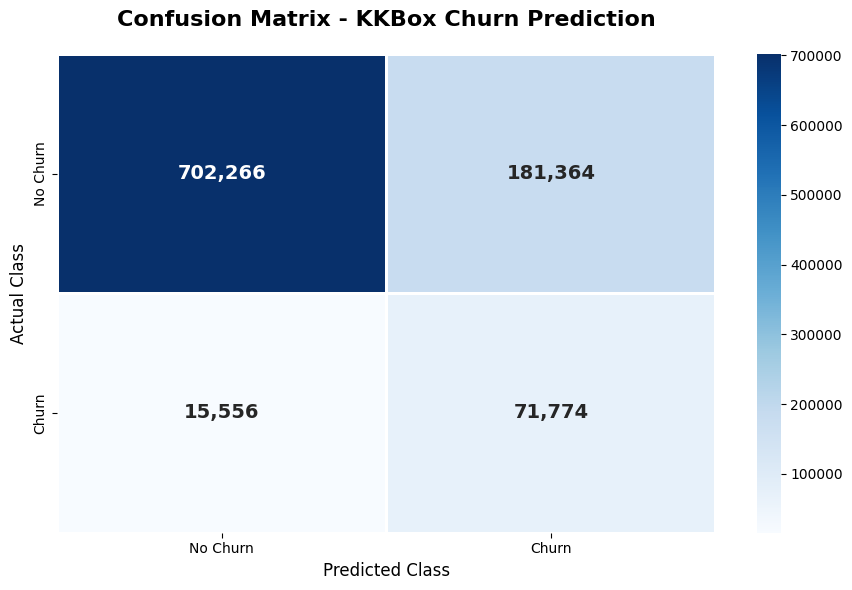


             CONFUSION MATRIX INTERPRETATION

TRUE NEGATIVES (TN): 702,266
Actual non-churners correctly predicted as non-churners.

FALSE POSITIVES (FP): 181,364
Actual non-churners incorrectly predicted as churners.

FALSE NEGATIVES (FN): 15,556
Actual churners incorrectly predicted as non-churners.

TRUE POSITIVES (TP): 71,774
Actual churners correctly predicted as churners.

BUSINESS MEANING:

True Positives:
Customers who may need retention attention and were
successfully identified.

False Positives:
Customers who may receive unnecessary retention offers.

False Negatives:
Customers who may churn without being identified.

True Negatives:
Customers correctly identified as not churning.

A good churn model should identify many true positives
while keeping false positives at a manageable level.



In [ ]:
# ==========================================================
# CONFUSION MATRIX - ENSEMBLE MODEL
# ==========================================================

cm = confusion_matrix(y_xai, pred_xai)

plt.figure(figsize=(9, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt=",",
    cmap="Blues",
    linewidths=1,
    linecolor="white",
    xticklabels=["No Churn", "Churn"],
    yticklabels=["No Churn", "Churn"],
    annot_kws={"size": 14, "weight": "bold"}
)

plt.title(
    "Confusion Matrix - KKBox Churn Prediction",
    fontsize=16,
    fontweight="bold",
    pad=20
)

plt.xlabel("Predicted Class", fontsize=12)
plt.ylabel("Actual Class", fontsize=12)
plt.tight_layout()
plt.show()

tn, fp, fn, tp = cm.ravel()

print("\n" + "=" * 65)
print("             CONFUSION MATRIX INTERPRETATION")
print("=" * 65)

print(f"""
TRUE NEGATIVES (TN): {tn:,}
Actual non-churners correctly predicted as non-churners.

FALSE POSITIVES (FP): {fp:,}
Actual non-churners incorrectly predicted as churners.

FALSE NEGATIVES (FN): {fn:,}
Actual churners incorrectly predicted as non-churners.

TRUE POSITIVES (TP): {tp:,}
Actual churners correctly predicted as churners.

BUSINESS MEANING:

True Positives:
Customers who may need retention attention and were
successfully identified.

False Positives:
Customers who may receive unnecessary retention offers.

False Negatives:
Customers who may churn without being identified.

True Negatives:
Customers correctly identified as not churning.

A good churn model should identify many true positives
while keeping false positives at a manageable level.
""")

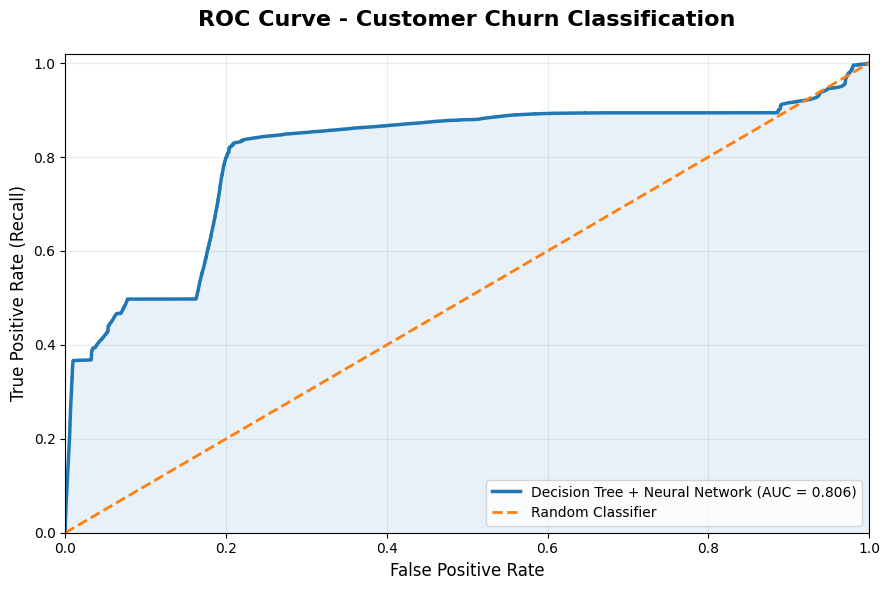


                ROC CURVE INTERPRETATION

ROC-AUC SCORE: 0.8061

X-AXIS - FALSE POSITIVE RATE:
Shows the proportion of actual non-churners incorrectly
classified as churners.

Y-AXIS - TRUE POSITIVE RATE:
Shows the proportion of actual churners correctly detected.
This is also called Recall.

BLUE CURVE:
Shows the model's performance at different probability
classification thresholds.

DASHED DIAGONAL:
Represents random classification. A curve closer to the
top-left generally indicates better discrimination.

AUC:
Represents the area under the ROC curve. A higher value
indicates better separation between the two classes.

PROJECT INTERPRETATION:
The ROC curve evaluates the ensemble's ability to rank
churners above non-churners across different thresholds.

It does not tell us which threshold is best for the business.



In [ ]:
# ==========================================================
# ROC CURVE - ENSEMBLE MODEL
# ==========================================================

fpr, tpr, thresholds_roc = roc_curve(y_xai, prob_xai)
roc_auc = roc_auc_score(y_xai, prob_xai)

plt.figure(figsize=(9, 6))

plt.plot(
    fpr, tpr,
    linewidth=2.5,
    label=f"Decision Tree + Neural Network (AUC = {roc_auc:.3f})"
)

plt.plot(
    [0, 1], [0, 1],
    linestyle="--",
    linewidth=2,
    label="Random Classifier"
)

plt.fill_between(fpr, tpr, alpha=0.10)

plt.title(
    "ROC Curve - Customer Churn Classification",
    fontsize=16,
    fontweight="bold",
    pad=20
)

plt.xlabel("False Positive Rate", fontsize=12)
plt.ylabel("True Positive Rate (Recall)", fontsize=12)

plt.xlim(0, 1)
plt.ylim(0, 1.02)
plt.legend(loc="lower right")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

print("\n" + "=" * 65)
print("                ROC CURVE INTERPRETATION")
print("=" * 65)

print(f"""
ROC-AUC SCORE: {roc_auc:.4f}

X-AXIS - FALSE POSITIVE RATE:
Shows the proportion of actual non-churners incorrectly
classified as churners.

Y-AXIS - TRUE POSITIVE RATE:
Shows the proportion of actual churners correctly detected.
This is also called Recall.

BLUE CURVE:
Shows the model's performance at different probability
classification thresholds.

DASHED DIAGONAL:
Represents random classification. A curve closer to the
top-left generally indicates better discrimination.

AUC:
Represents the area under the ROC curve. A higher value
indicates better separation between the two classes.

PROJECT INTERPRETATION:
The ROC curve evaluates the ensemble's ability to rank
churners above non-churners across different thresholds.

It does not tell us which threshold is best for the business.
""")

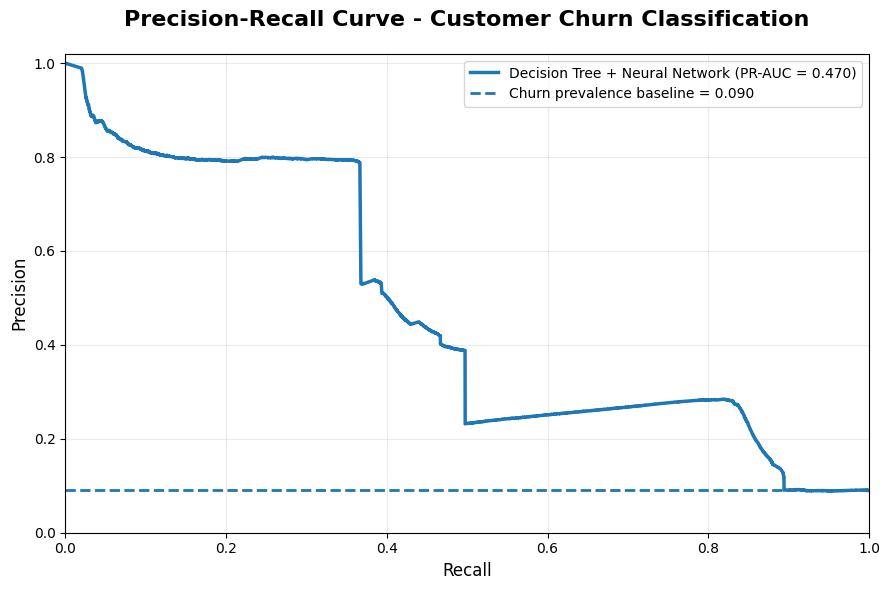


          PRECISION-RECALL CURVE INTERPRETATION

PR-AUC SCORE: 0.4699
CHURN PREVALENCE: 0.0899

X-AXIS - RECALL:
Shows how many actual churners are successfully identified.

Y-AXIS - PRECISION:
Shows how many predicted churners are actually churners.

CURVE:
Displays the trade-off between precision and recall
at different classification thresholds.

DASHED BASELINE:
Represents the churn proportion in the actual dataset.
It provides a reference for evaluating precision.

PROJECT INTERPRETATION:
A higher recall means we identify more actual churners.
However, increasing recall can reduce precision, causing
more non-churners to be incorrectly flagged.

The PR curve is particularly useful for our project because
churners form a minority of the customer population.

BUSINESS IMPORTANCE:
A company must decide whether it is more costly to miss a
potential churner or to offer retention incentives to a
customer who would have stayed anyway.



In [ ]:
# ==========================================================
# PRECISION-RECALL CURVE - ENSEMBLE MODEL
# ==========================================================

precision_values, recall_values, pr_thresholds = (
    precision_recall_curve(y_xai, prob_xai)
)

pr_auc = average_precision_score(y_xai, prob_xai)

churn_prevalence = np.mean(y_xai)

plt.figure(figsize=(9, 6))

plt.plot(
    recall_values,
    precision_values,
    linewidth=2.5,
    label=f"Decision Tree + Neural Network (PR-AUC = {pr_auc:.3f})"
)

plt.axhline(
    y=churn_prevalence,
    linestyle="--",
    linewidth=2,
    label=f"Churn prevalence baseline = {churn_prevalence:.3f}"
)

plt.title(
    "Precision-Recall Curve - Customer Churn Classification",
    fontsize=16,
    fontweight="bold",
    pad=20
)

plt.xlabel("Recall", fontsize=12)
plt.ylabel("Precision", fontsize=12)

plt.xlim(0, 1)
plt.ylim(0, 1.02)
plt.legend(loc="upper right")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

print("\n" + "=" * 65)
print("          PRECISION-RECALL CURVE INTERPRETATION")
print("=" * 65)

print(f"""
PR-AUC SCORE: {pr_auc:.4f}
CHURN PREVALENCE: {churn_prevalence:.4f}

X-AXIS - RECALL:
Shows how many actual churners are successfully identified.

Y-AXIS - PRECISION:
Shows how many predicted churners are actually churners.

CURVE:
Displays the trade-off between precision and recall
at different classification thresholds.

DASHED BASELINE:
Represents the churn proportion in the actual dataset.
It provides a reference for evaluating precision.

PROJECT INTERPRETATION:
A higher recall means we identify more actual churners.
However, increasing recall can reduce precision, causing
more non-churners to be incorrectly flagged.

The PR curve is particularly useful for our project because
churners form a minority of the customer population.

BUSINESS IMPORTANCE:
A company must decide whether it is more costly to miss a
potential churner or to offer retention incentives to a
customer who would have stayed anyway.
""")

In [ ]:
# ==========================================================
# FINAL EXPLAINABLE AI SUMMARY
# ==========================================================

print("\n" + "=" * 70)
print("       KKBOX CUSTOMER CHURN - EXPLAINABLE AI REPORT")
print("=" * 70)

print("\n1. GLOBAL EXPLAINABILITY")
print("SHAP Summary and Bar plots identify the features that")
print("influence the Decision Tree's predictions.")

print("\n2. LOCAL EXPLAINABILITY")
print("SHAP Waterfall explains an individual Decision Tree prediction.")
print("LIME explains an individual ensemble prediction.")

print("\n3. MODEL PERFORMANCE")

for name, value in metrics.items():
    print(f"{name:<15}: {value:.4f}")

print("\n4. CONFUSION MATRIX")
print(f"True Positives : {tp:,}")
print(f"True Negatives : {tn:,}")
print(f"False Positives: {fp:,}")
print(f"False Negatives: {fn:,}")

print("\n5. OVERALL FINDING")

if metrics["Recall"] > metrics["Precision"]:
    print("The model identifies a relatively high proportion of")
    print("actual churners, but generates more false churn alerts.")
else:
    print("The model has relatively higher precision than recall.")
    print("Some actual churners may remain undetected.")

print("\n6. BUSINESS APPLICATION")
print("The explanations can help the company understand")
print("which customer patterns influence churn predictions.")
print("Retention strategies can then be investigated using")
print("these insights.")

print("\nIMPORTANT LIMITATION")
print("SHAP and LIME explain model behaviour, not causation.")
print("V2 results require validation of feature compatibility")
print("and prediction-time data availability.")

print("\n" + "=" * 70)
print("             XAI ANALYSIS COMPLETED")
print("=" * 70)


       KKBOX CUSTOMER CHURN - EXPLAINABLE AI REPORT

1. GLOBAL EXPLAINABILITY
SHAP Summary and Bar plots identify the features that
influence the Decision Tree's predictions.

2. LOCAL EXPLAINABILITY
SHAP Waterfall explains an individual Decision Tree prediction.
LIME explains an individual ensemble prediction.

3. MODEL PERFORMANCE
Accuracy       : 0.7972
Precision      : 0.2835
Recall         : 0.8219
F1 Score       : 0.4216
ROC-AUC        : 0.8061
PR-AUC         : 0.4699

4. CONFUSION MATRIX
True Positives : 71,774
True Negatives : 702,266
False Positives: 181,364
False Negatives: 15,556

5. OVERALL FINDING
The model identifies a relatively high proportion of
actual churners, but generates more false churn alerts.

6. BUSINESS APPLICATION
The explanations can help the company understand
which customer patterns influence churn predictions.
Retention strategies can then be investigated using
these insights.

IMPORTANT LIMITATION
SHAP and LIME explain model behaviour, not causation.
V